# Puhinui High-Water-Risk Classification

This notebook reconstructs and validates the Puhinui hourly dataset, defines a 24-hour high-water-risk target, engineers hydrological features, and compares Random Forest and XGBoost classifiers using chronological training, validation, and test periods.

## 1. Data Loading and Station Audit

In [1]:
# Code cell 1 - Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option(
    "display.float_format",
    lambda value: f"{value:.3f}"
)

In [2]:
# Code cell 2 - File paths

file_paths = {
    "rain_primary": Path(
        r"C:\Users\kgeet\Downloads\740945.csv"
    ),
    "rain_support": Path(
        r"C:\Users\kgeet\Downloads\740815.csv"
    ),
    "discharge_primary": Path(
        r"C:\Users\kgeet\Downloads\43807(1).csv"
    ),
    "level_primary": Path(
        r"C:\Users\kgeet\Downloads\43807(2).csv"
    )
}

for dataset_name, file_path in file_paths.items():
    print(
        dataset_name,
        "-",
        file_path.name,
        "- exists:",
        file_path.exists()
    )

rain_primary - 740945.csv - exists: True
rain_support - 740815.csv - exists: True
discharge_primary - 43807(1).csv - exists: True
level_primary - 43807(2).csv - exists: True


In [3]:
# Code cell 3 - Reusable gauge-data loader

def load_gauge_data(file_path, value_name):
    """
    Load an Environment Auckland hourly gauge export.

    The first row contains dataset metadata and the second row contains
    the actual column headers.
    """
    data = pd.read_csv(
        file_path,
        skiprows=1
    )

    if data.shape[1] != 3:
        raise ValueError(
            f"{file_path.name} contains {data.shape[1]} columns; "
            "three columns were expected."
        )

    data = data.iloc[:, :3].copy()

    data.columns = [
        "timestamp",
        "interval_end",
        value_name
    ]

    data["timestamp"] = pd.to_datetime(
        data["timestamp"],
        errors="coerce"
    )

    data["interval_end"] = pd.to_datetime(
        data["interval_end"],
        errors="coerce"
    )

    data[value_name] = pd.to_numeric(
        data[value_name],
        errors="coerce"
    )

    data = (
        data
        .dropna(subset=["timestamp"])
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    return data

In [4]:
# Code cell 4 - Load and initially inspect the four datasets

rain_primary = load_gauge_data(
    file_paths["rain_primary"],
    "rainfall_primary_mm"
)

rain_support = load_gauge_data(
    file_paths["rain_support"],
    "rainfall_support_mm"
)

discharge_primary = load_gauge_data(
    file_paths["discharge_primary"],
    "discharge_m3s"
)

level_primary = load_gauge_data(
    file_paths["level_primary"],
    "water_level_m"
)


datasets = {
    "Rainfall primary - 740945": (
        rain_primary,
        "rainfall_primary_mm"
    ),
    "Rainfall historical support - 740815": (
        rain_support,
        "rainfall_support_mm"
    ),
    "River discharge - 43807": (
        discharge_primary,
        "discharge_m3s"
    ),
    "River water level - 43807": (
        level_primary,
        "water_level_m"
    )
}


audit_rows = []

for dataset_name, (data, value_column) in datasets.items():
    duplicated_timestamps = data["timestamp"].duplicated(
        keep=False
    )

    audit_rows.append({
        "dataset": dataset_name,
        "rows": len(data),
        "unique_timestamps": data["timestamp"].nunique(),
        "duplicate_timestamps": int(
            data.loc[
                duplicated_timestamps,
                "timestamp"
            ].nunique()
        ),
        "beginning": data["timestamp"].min(),
        "ending": data["timestamp"].max(),
        "missing_values": int(
            data[value_column].isna().sum()
        ),
        "negative_values": int(
            (data[value_column] < 0).sum()
        )
    })


initial_station_audit = (
    pd.DataFrame(audit_rows)
    .set_index("dataset")
)

display(initial_station_audit)

,rows,unique_timestamps,duplicate_timestamps,beginning,ending,missing_values,negative_values
dataset,,,,,,,
Rainfall primary - 740945,59839,59833,6,2019-03-06 00:00:00,2026-01-01 00:00:00,6,0
Rainfall historical support - 740815,29677,29674,3,2015-01-01 01:00:00,2018-05-21 10:00:00,3,0
River discharge - 43807,101040,101040,0,2015-01-01 00:00:00,2026-07-11 23:00:00,582,0
River water level - 43807,101040,101040,0,2015-01-01 00:00:00,2026-07-11 23:00:00,580,0


## 2. Duplicate Resolution and Hourly Alignment

Duplicate rainfall timestamps are inspected before merging. Each duplicated timestamp contains one valid zero-rainfall observation and one missing observation. The valid observation will be retained. If any duplicated timestamp contains conflicting non-missing rainfall values, the cleaning code will stop for manual inspection.

In [5]:
# Code cell 5 - Inspect duplicated rainfall timestamps

def show_duplicate_timestamps(
    data,
    dataset_name
):
    duplicate_rows = data[
        data.duplicated(
            "timestamp",
            keep=False
        )
    ].sort_values("timestamp")

    duplicate_timestamp_count = (
        duplicate_rows["timestamp"].nunique()
    )

    print(
        f"{dataset_name}: "
        f"{duplicate_timestamp_count} duplicated timestamps, "
        f"{len(duplicate_rows)} involved rows"
    )

    if not duplicate_rows.empty:
        display(duplicate_rows)


show_duplicate_timestamps(
    rain_primary,
    "Primary rainfall - 740945"
)

show_duplicate_timestamps(
    rain_support,
    "Historical rainfall support - 740815"
)

Primary rainfall - 740945: 6 duplicated timestamps, 12 involved rows


,timestamp,interval_end,rainfall_primary_mm
7224,2020-01-01,NaT,0.000
7225,2020-01-01,NaT,NaN
16009,2021-01-01,NaT,NaN
16010,2021-01-01,NaT,0.000
24770,2022-01-01,NaT,0.000
24771,2022-01-01,NaT,NaN
33531,2023-01-01,NaT,0.000
33532,2023-01-01,NaT,NaN
42292,2024-01-01,NaT,NaN
42293,2024-01-01,NaT,0.000


Historical rainfall support - 740815: 3 duplicated timestamps, 6 involved rows


,timestamp,interval_end,rainfall_support_mm
8759,2016-01-01,NaT,0.000
8760,2016-01-01,NaT,NaN
17544,2017-01-01,NaT,0.000
17545,2017-01-01,NaT,NaN
26305,2018-01-01,NaT,0.000
26306,2018-01-01,NaT,NaN


In [6]:
# Code cell 6 - Resolve duplicated rainfall timestamps safely

def resolve_duplicate_timestamps(
    data,
    value_column,
    dataset_name
):
    data = data.copy()

    # Count distinct valid measurements at every timestamp
    distinct_valid_values = (
        data.groupby("timestamp")[value_column]
        .apply(
            lambda values:
            values.dropna().nunique()
        )
    )

    # More than one valid value would indicate a genuine conflict
    conflicting_timestamps = distinct_valid_values[
        distinct_valid_values > 1
    ].index

    if len(conflicting_timestamps) > 0:
        display(
            data[
                data["timestamp"].isin(
                    conflicting_timestamps
                )
            ].sort_values("timestamp")
        )

        raise ValueError(
            f"{dataset_name} contains conflicting "
            "non-missing measurements at duplicated timestamps."
        )

    rows_before = len(data)

    # Place valid observations before missing observations
    data["_measurement_available"] = (
        data[value_column].notna()
    )

    data = (
        data
        .sort_values(
            [
                "timestamp",
                "_measurement_available"
            ],
            ascending=[True, False]
        )
        .drop_duplicates(
            "timestamp",
            keep="first"
        )
        .drop(
            columns="_measurement_available"
        )
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    print(
        f"{dataset_name}: "
        f"{rows_before:,} rows -> "
        f"{len(data):,} unique hourly rows"
    )

    return data


rain_primary = resolve_duplicate_timestamps(
    rain_primary,
    "rainfall_primary_mm",
    "Primary rainfall - 740945"
)

rain_support = resolve_duplicate_timestamps(
    rain_support,
    "rainfall_support_mm",
    "Historical rainfall support - 740815"
)

Primary rainfall - 740945: 59,839 rows -> 59,833 unique hourly rows
Historical rainfall support - 740815: 29,677 rows -> 29,674 unique hourly rows


In [7]:
# Code cell 7 - Verify rainfall datasets after duplicate resolution

duplicate_resolution_check = pd.DataFrame({
    "dataset": [
        "rain_primary_740945",
        "rain_support_740815"
    ],
    "rows": [
        len(rain_primary),
        len(rain_support)
    ],
    "unique_timestamps": [
        rain_primary["timestamp"].nunique(),
        rain_support["timestamp"].nunique()
    ],
    "duplicate_timestamps": [
        rain_primary["timestamp"].duplicated().sum(),
        rain_support["timestamp"].duplicated().sum()
    ],
    "missing_values": [
        rain_primary["rainfall_primary_mm"].isna().sum(),
        rain_support["rainfall_support_mm"].isna().sum()
    ]
}).set_index("dataset")

display(duplicate_resolution_check)

,rows,unique_timestamps,duplicate_timestamps,missing_values
dataset,,,,
rain_primary_740945,59833,59833,0,0
rain_support_740815,29674,29674,0,0


## 3. Create the Hourly Puhinui Base Dataset

A continuous hourly timeline is created for the fixed study period. Rainfall station 740945 is the current primary gauge, while station 740815 provides the earlier historical rainfall record. The two rainfall records do not overlap, and the uncovered period between them remains missing rather than being interpreted as zero rainfall. River discharge and water level are obtained from station 43807. No secondary river station is available for substitution.

In [8]:
# Code cell 8 - Define the fixed Puhinui study period

study_start = pd.Timestamp(
    "2015-01-01 01:00:00"
)

study_end = pd.Timestamp(
    "2026-01-01 00:00:00"
)

hourly_timeline = pd.DataFrame({
    "timestamp": pd.date_range(
        start=study_start,
        end=study_end,
        freq="h"
    )
})

print(
    "Study period:",
    study_start,
    "to",
    study_end
)

print(
    "Expected hourly rows:",
    len(hourly_timeline)
)

Study period: 2015-01-01 01:00:00 to 2026-01-01 00:00:00
Expected hourly rows: 96432


In [9]:
# Code cell 9 - Merge rainfall, discharge and water-level measurements

puhinui_base = (
    hourly_timeline
    .merge(
        rain_primary[
            [
                "timestamp",
                "rainfall_primary_mm"
            ]
        ],
        on="timestamp",
        how="left"
    )
    .merge(
        rain_support[
            [
                "timestamp",
                "rainfall_support_mm"
            ]
        ],
        on="timestamp",
        how="left"
    )
    .merge(
        discharge_primary[
            [
                "timestamp",
                "discharge_m3s"
            ]
        ],
        on="timestamp",
        how="left"
    )
    .merge(
        level_primary[
            [
                "timestamp",
                "water_level_m"
            ]
        ],
        on="timestamp",
        how="left"
    )
)


# Use the current rainfall gauge where available.
# Use the historical gauge for the earlier record.
puhinui_base["rainfall_mm"] = (
    puhinui_base["rainfall_primary_mm"]
    .combine_first(
        puhinui_base["rainfall_support_mm"]
    )
)


puhinui_base["rainfall_source"] = np.select(
    [
        puhinui_base[
            "rainfall_primary_mm"
        ].notna(),
        (
            puhinui_base[
                "rainfall_primary_mm"
            ].isna()
            & puhinui_base[
                "rainfall_support_mm"
            ].notna()
        )
    ],
    [
        "740945_primary",
        "740815_historical"
    ],
    default="missing"
)


puhinui_base["rainfall_substituted"] = (
    puhinui_base["rainfall_source"]
    == "740815_historical"
)


# River variables use station 43807 only
puhinui_base["discharge_source"] = np.where(
    puhinui_base["discharge_m3s"].notna(),
    "43807_primary",
    "missing"
)

puhinui_base["water_level_source"] = np.where(
    puhinui_base["water_level_m"].notna(),
    "43807_primary",
    "missing"
)

puhinui_base["discharge_substituted"] = False
puhinui_base["water_level_substituted"] = False


# Retain the same base structure used for the other catchments
puhinui_base = puhinui_base[[
    "timestamp",
    "rainfall_mm",
    "rainfall_substituted",
    "rainfall_source",
    "discharge_m3s",
    "water_level_m",
    "discharge_substituted",
    "water_level_substituted",
    "discharge_source",
    "water_level_source"
]]


display(puhinui_base.head())

print(
    "Puhinui base shape:",
    puhinui_base.shape
)

,timestamp,rainfall_mm,rainfall_substituted,rainfall_source,discharge_m3s,water_level_m,discharge_substituted,water_level_substituted,discharge_source,water_level_source
0,2015-01-01 01:00:00,2.330,True,740815_historical,0.306,0.290,False,False,43807_primary,43807_primary
1,2015-01-01 02:00:00,1.390,True,740815_historical,0.168,0.225,False,False,43807_primary,43807_primary
2,2015-01-01 03:00:00,0.000,True,740815_historical,0.127,0.199,False,False,43807_primary,43807_primary
3,2015-01-01 04:00:00,0.000,True,740815_historical,0.120,0.194,False,False,43807_primary,43807_primary
4,2015-01-01 05:00:00,0.000,True,740815_historical,0.134,0.204,False,False,43807_primary,43807_primary


Puhinui base shape: (96432, 10)


In [10]:
# Code cell 10 - Audit the merged hourly Puhinui dataset

measurement_availability = pd.DataFrame({
    "measurement": [
        "rainfall_mm",
        "discharge_m3s",
        "water_level_m"
    ],
    "available": [
        puhinui_base["rainfall_mm"].notna().sum(),
        puhinui_base["discharge_m3s"].notna().sum(),
        puhinui_base["water_level_m"].notna().sum()
    ],
    "missing": [
        puhinui_base["rainfall_mm"].isna().sum(),
        puhinui_base["discharge_m3s"].isna().sum(),
        puhinui_base["water_level_m"].isna().sum()
    ]
}).set_index("measurement")

measurement_availability["availability_percent"] = (
    measurement_availability["available"]
    / len(puhinui_base)
    * 100
)


rainfall_source_counts = (
    puhinui_base["rainfall_source"]
    .value_counts(dropna=False)
    .rename_axis("rainfall_source")
    .to_frame("hours")
)


print("Rainfall source counts:")
display(rainfall_source_counts)

print("\nMerged measurement availability:")
display(
    measurement_availability.round(3)
)

print(
    "\nDuplicate timestamps:",
    puhinui_base["timestamp"].duplicated().sum()
)

print(
    "Total hourly rows:",
    len(puhinui_base)
)

Rainfall source counts:


,hours
rainfall_source,
740945_primary,59833
740815_historical,29674
missing,6925



Merged measurement availability:


,available,missing,availability_percent
measurement,,,
rainfall_mm,89507,6925,92.819
discharge_m3s,95862,570,99.409
water_level_m,95863,569,99.410



Duplicate timestamps: 0
Total hourly rows: 96432


## 4. Missing-Data Treatment

The two Puhinui rainfall gauges provide 89,507 hourly measurements across the study period. Station 740815 supplies the historical record until 21 May 2018, while station 740945 supplies the current record from 6 March 2019. The uncovered 6,925-hour interval between these records remains missing.

Station 43807 contains 570 missing discharge measurements and 569 missing water-level measurements. No secondary Puhinui river station is available for substitution. Missing measurements are not filled with zero or interpolated across the complete dataset. Missingness indicators are retained, and rows requiring unavailable measurements will later be excluded after feature engineering.

In [11]:
# Code cell 11 - Preserve measurements and record missingness

puhinui_preprocessed = puhinui_base.copy()

puhinui_preprocessed["rainfall_missing"] = (
    puhinui_preprocessed["rainfall_mm"].isna()
)

puhinui_preprocessed["discharge_missing"] = (
    puhinui_preprocessed["discharge_m3s"].isna()
)

puhinui_preprocessed["water_level_missing"] = (
    puhinui_preprocessed["water_level_m"].isna()
)


print(
    "Preprocessed dataset shape:",
    puhinui_preprocessed.shape
)

display(
    puhinui_preprocessed[[
        "rainfall_missing",
        "discharge_missing",
        "water_level_missing"
    ]]
    .sum()
    .to_frame("missing_hours")
)

Preprocessed dataset shape: (96432, 13)


,missing_hours
rainfall_missing,6925
discharge_missing,570
water_level_missing,569


In [12]:
# Code cell 12 - Summarise consecutive missing-data episodes

def summarise_missing_episodes(
    data,
    column
):
    missing = data[column].isna()

    if not missing.any():
        return {
            "missing_hours": 0,
            "missing_episodes": 0,
            "longest_episode_hours": 0,
            "median_episode_hours": 0
        }

    episode_group = (
        missing
        .ne(
            missing.shift(
                fill_value=False
            )
        )
        .cumsum()
    )

    episode_lengths = (
        missing[missing]
        .groupby(
            episode_group[missing]
        )
        .size()
    )

    return {
        "missing_hours": int(
            missing.sum()
        ),
        "missing_episodes": int(
            len(episode_lengths)
        ),
        "longest_episode_hours": int(
            episode_lengths.max()
        ),
        "median_episode_hours": float(
            episode_lengths.median()
        )
    }


missing_episode_audit = pd.DataFrame({
    "rainfall_mm": summarise_missing_episodes(
        puhinui_preprocessed,
        "rainfall_mm"
    ),
    "discharge_m3s": summarise_missing_episodes(
        puhinui_preprocessed,
        "discharge_m3s"
    ),
    "water_level_m": summarise_missing_episodes(
        puhinui_preprocessed,
        "water_level_m"
    )
}).T

display(missing_episode_audit)

,missing_hours,missing_episodes,longest_episode_hours,median_episode_hours
rainfall_mm,6925.000,1.000,6925.000,6925.000
discharge_m3s,570.000,36.000,351.000,1.000
water_level_m,569.000,37.000,351.000,1.000


## 5. Exploratory Data Analysis

This section examines the distributions and temporal patterns of rainfall, river discharge, and river water level before feature engineering and model development.

In [13]:
# Code cell 13 - Summary statistics for core measurements

core_measurements = [
    "rainfall_mm",
    "discharge_m3s",
    "water_level_m"
]

measurement_summary = (
    puhinui_preprocessed[
        core_measurements
    ]
    .describe(
        percentiles=[
            0.50,
            0.75,
            0.90,
            0.95,
            0.99,
            0.995
        ]
    )
    .T
    .round(3)
)

display(measurement_summary)

,count,mean,std,min,50%,75%,90%,95%,99%,99.5%,max
rainfall_mm,89507.000,0.150,0.850,0.000,0.000,0.000,0.000,0.530,3.500,5.000,43.120
discharge_m3s,95862.000,0.265,0.865,0.008,0.101,0.205,0.495,0.925,2.879,4.449,66.466
water_level_m,95863.000,0.218,0.674,0.000,0.181,0.245,0.358,0.459,0.738,0.890,204.010


In [14]:
# Code cell 14 - Inspect extreme water-level observations

extreme_water_levels = (
    puhinui_preprocessed[
        [
            "timestamp",
            "rainfall_mm",
            "discharge_m3s",
            "water_level_m",
            "water_level_source",
            "water_level_missing"
        ]
    ]
    .sort_values(
        "water_level_m",
        ascending=False
    )
    .head(20)
    .reset_index(drop=True)
)

display(extreme_water_levels)

,timestamp,rainfall_mm,discharge_m3s,water_level_m,water_level_source,water_level_missing
0,2023-01-16 13:00:00,0.000,0.134,204.010,43807_primary,False
1,2023-02-16 08:00:00,0.000,0.276,19.470,43807_primary,False
2,2023-01-27 19:00:00,29.457,66.466,2.728,43807_primary,False
3,2023-01-27 18:00:00,11.215,63.310,2.671,43807_primary,False
4,2023-01-27 20:00:00,7.958,61.310,2.634,43807_primary,False
5,2023-01-27 21:00:00,1.410,47.411,2.355,43807_primary,False
6,2023-01-27 17:00:00,18.403,34.733,2.061,43807_primary,False
7,2023-05-09 14:00:00,6.246,31.248,1.972,43807_primary,False
8,2023-05-09 13:00:00,18.550,31.209,1.971,43807_primary,False
9,2023-01-27 16:00:00,9.946,29.261,1.920,43807_primary,False


In [15]:
# Code cell 15 - Inspect the context around suspected water-level errors

suspected_error_times = pd.to_datetime([
    "2023-01-16 13:00:00",
    "2023-02-16 08:00:00"
])

context_windows = []

for error_time in suspected_error_times:
    context = puhinui_preprocessed.loc[
        puhinui_preprocessed["timestamp"].between(
            error_time - pd.Timedelta(hours=3),
            error_time + pd.Timedelta(hours=3)
        ),
        [
            "timestamp",
            "rainfall_mm",
            "discharge_m3s",
            "water_level_m"
        ]
    ].copy()

    context["suspected_error_time"] = error_time
    context_windows.append(context)

water_level_error_context = pd.concat(
    context_windows,
    ignore_index=True
)

display(water_level_error_context)

,timestamp,rainfall_mm,discharge_m3s,water_level_m,suspected_error_time
0,2023-01-16 10:00:00,0.000,0.142,0.209,2023-01-16 13:00:00
1,2023-01-16 11:00:00,0.000,0.140,0.208,2023-01-16 13:00:00
2,2023-01-16 12:00:00,0.000,NaN,NaN,2023-01-16 13:00:00
3,2023-01-16 13:00:00,0.000,0.134,204.010,2023-01-16 13:00:00
4,2023-01-16 14:00:00,0.000,2.572,0.703,2023-01-16 13:00:00
5,2023-01-16 15:00:00,0.000,0.130,0.201,2023-01-16 13:00:00
6,2023-01-16 16:00:00,0.000,0.128,0.200,2023-01-16 13:00:00
7,2023-02-16 05:00:00,0.000,0.291,0.284,2023-02-16 08:00:00
8,2023-02-16 06:00:00,0.000,0.284,0.281,2023-02-16 08:00:00
9,2023-02-16 07:00:00,0.000,0.281,0.280,2023-02-16 08:00:00


In [16]:
# Code cell 16 - Remove confirmed invalid water-level observations

puhinui_preprocessed[
    "water_level_original_m"
] = puhinui_preprocessed[
    "water_level_m"
]

puhinui_preprocessed[
    "water_level_invalid"
] = puhinui_preprocessed[
    "timestamp"
].isin(suspected_error_times)

puhinui_preprocessed.loc[
    puhinui_preprocessed[
        "water_level_invalid"
    ],
    "water_level_m"
] = np.nan

puhinui_preprocessed[
    "water_level_missing"
] = puhinui_preprocessed[
    "water_level_m"
].isna()

print(
    "Invalid water-level observations removed:",
    puhinui_preprocessed[
        "water_level_invalid"
    ].sum()
)

print(
    "Water-level missing hours after removal:",
    puhinui_preprocessed[
        "water_level_missing"
    ].sum()
)

display(
    puhinui_preprocessed.loc[
        puhinui_preprocessed[
            "water_level_invalid"
        ],
        [
            "timestamp",
            "water_level_original_m",
            "water_level_m",
            "water_level_invalid",
            "water_level_missing"
        ]
    ]
)

Invalid water-level observations removed: 2
Water-level missing hours after removal: 571


,timestamp,water_level_original_m,water_level_m,water_level_invalid,water_level_missing
70500,2023-01-16 13:00:00,204.010,NaN,True,True
71239,2023-02-16 08:00:00,19.470,NaN,True,True


In [17]:
# Code cell 17 - Recalculate summary statistics after outlier removal

measurement_summary_cleaned = (
    puhinui_preprocessed[
        core_measurements
    ]
    .describe(
        percentiles=[
            0.50,
            0.75,
            0.90,
            0.95,
            0.99,
            0.995
        ]
    )
    .T
    .round(3)
)

display(measurement_summary_cleaned)

,count,mean,std,min,50%,75%,90%,95%,99%,99.5%,max
rainfall_mm,89507.000,0.150,0.850,0.000,0.000,0.000,0.000,0.530,3.500,5.000,43.120
discharge_m3s,95862.000,0.265,0.865,0.008,0.101,0.205,0.495,0.925,2.879,4.449,66.466
water_level_m,95861.000,0.216,0.132,0.000,0.181,0.245,0.358,0.458,0.738,0.887,2.728


In [18]:
# Code cell 18 - Update missing-episode audit after outlier removal

missing_episode_audit_cleaned = pd.DataFrame({
    "rainfall_mm": summarise_missing_episodes(
        puhinui_preprocessed,
        "rainfall_mm"
    ),
    "discharge_m3s": summarise_missing_episodes(
        puhinui_preprocessed,
        "discharge_m3s"
    ),
    "water_level_m": summarise_missing_episodes(
        puhinui_preprocessed,
        "water_level_m"
    )
}).T

display(missing_episode_audit_cleaned)

,missing_hours,missing_episodes,longest_episode_hours,median_episode_hours
rainfall_mm,6925.000,1.000,6925.000,6925.000
discharge_m3s,570.000,36.000,351.000,1.000
water_level_m,571.000,38.000,351.000,1.000


In [19]:
# Code cell 19 - Create daily measurement summaries

daily_measurements = (
    puhinui_preprocessed
    .set_index("timestamp")
    .resample("D")
    .agg({
        "rainfall_mm": "sum",
        "discharge_m3s": "mean",
        "water_level_m": "mean"
    })
)

# Preserve days where rainfall was entirely unavailable
daily_rainfall_available = (
    puhinui_preprocessed
    .set_index("timestamp")[
        "rainfall_mm"
    ]
    .resample("D")
    .count()
)

daily_measurements.loc[
    daily_rainfall_available == 0,
    "rainfall_mm"
] = np.nan

display(
    daily_measurements.head()
)

print(
    "Daily summary shape:",
    daily_measurements.shape
)

,rainfall_mm,discharge_m3s,water_level_m
timestamp,,,
2015-01-01,4.190,0.112,0.186
2015-01-02,0.000,0.044,0.130
2015-01-03,0.000,0.033,0.118
2015-01-04,0.000,0.030,0.114
2015-01-05,0.000,0.029,0.112


Daily summary shape: (4019, 3)


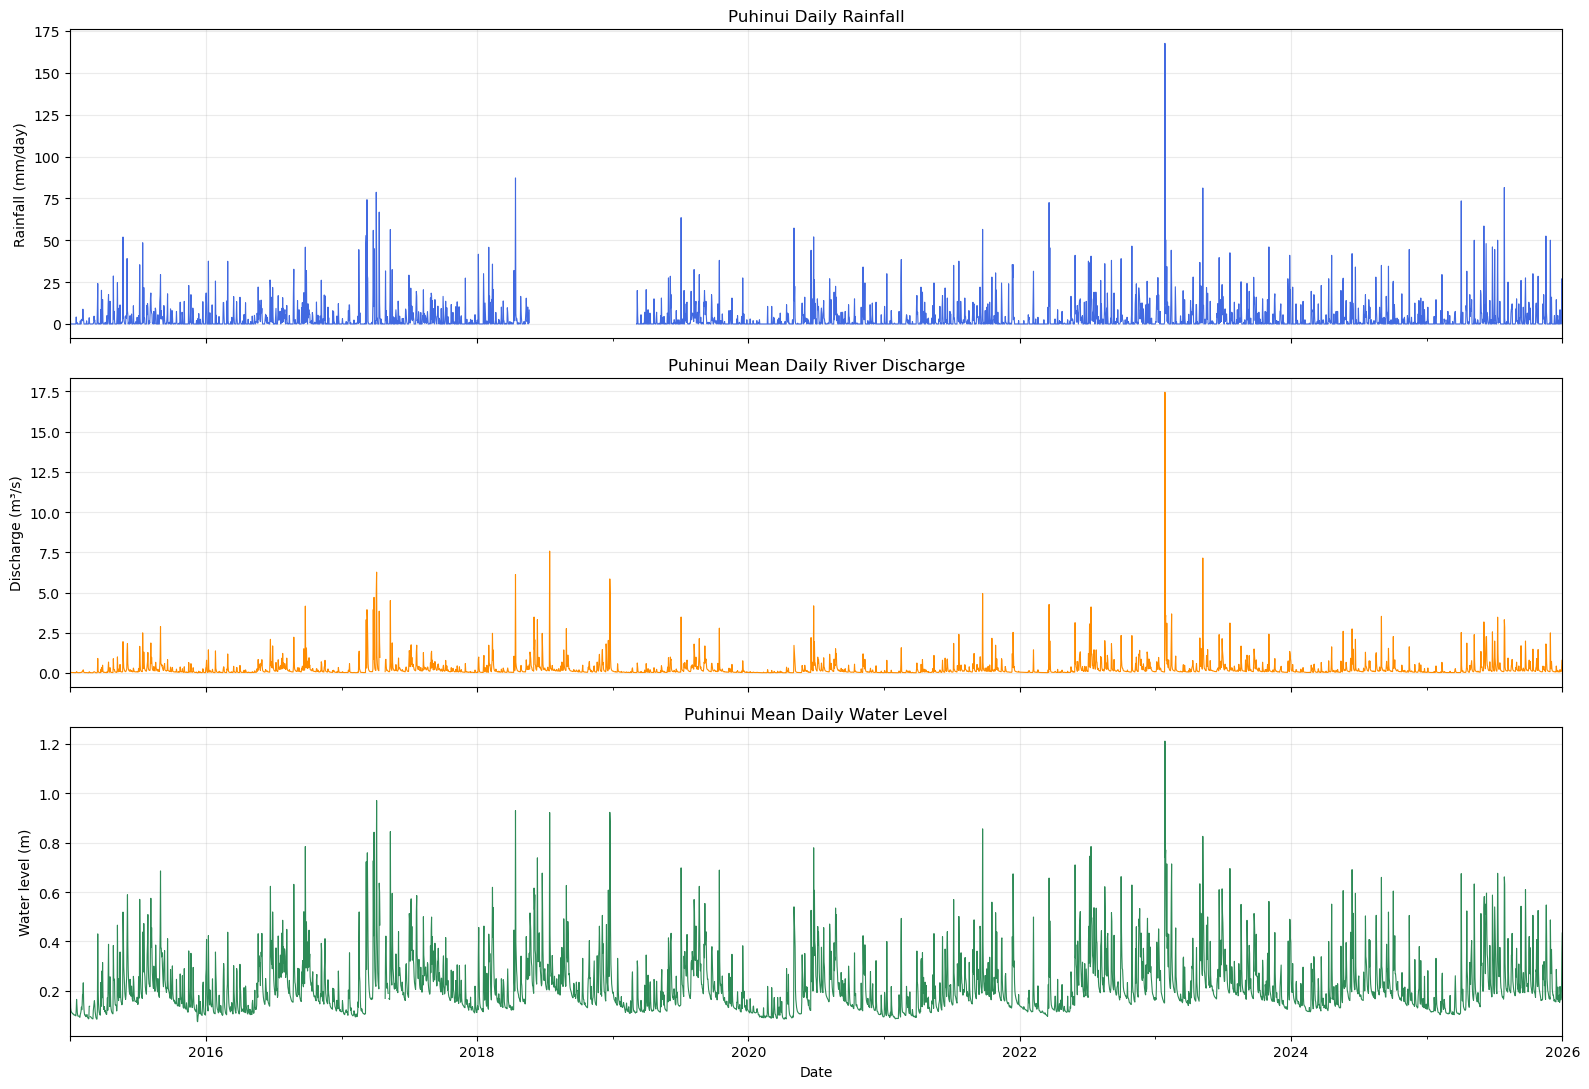

In [20]:
# Code cell 20 - Plot daily measurement patterns

fig, axes = plt.subplots(
    3,
    1,
    figsize=(16, 11),
    sharex=True
)

daily_measurements[
    "rainfall_mm"
].plot(
    ax=axes[0],
    color="royalblue",
    linewidth=0.8
)

axes[0].set_title(
    "Puhinui Daily Rainfall"
)
axes[0].set_ylabel(
    "Rainfall (mm/day)"
)

daily_measurements[
    "discharge_m3s"
].plot(
    ax=axes[1],
    color="darkorange",
    linewidth=0.8
)

axes[1].set_title(
    "Puhinui Mean Daily River Discharge"
)
axes[1].set_ylabel(
    "Discharge (m³/s)"
)

daily_measurements[
    "water_level_m"
].plot(
    ax=axes[2],
    color="seagreen",
    linewidth=0.8
)

axes[2].set_title(
    "Puhinui Mean Daily Water Level"
)
axes[2].set_ylabel(
    "Water level (m)"
)
axes[2].set_xlabel(
    "Date"
)

for axis in axes:
    axis.grid(
        alpha=0.25
    )

plt.tight_layout()
plt.show()

In [21]:
# Code cell 21 - Calculate monthly measurement patterns

seasonality_data = puhinui_preprocessed[
    [
        "timestamp",
        "rainfall_mm",
        "discharge_m3s",
        "water_level_m"
    ]
].copy()

seasonality_data[
    "month"
] = seasonality_data[
    "timestamp"
].dt.month

monthly_patterns = (
    seasonality_data
    .groupby("month")[
        [
            "rainfall_mm",
            "discharge_m3s",
            "water_level_m"
        ]
    ]
    .mean()
    .round(3)
)

display(monthly_patterns)

,rainfall_mm,discharge_m3s,water_level_m
month,,,
1,0.114,0.181,0.164
2,0.119,0.165,0.166
3,0.124,0.176,0.165
4,0.155,0.222,0.187
5,0.174,0.293,0.223
6,0.185,0.392,0.262
7,0.218,0.446,0.286
8,0.163,0.336,0.265
9,0.175,0.330,0.256


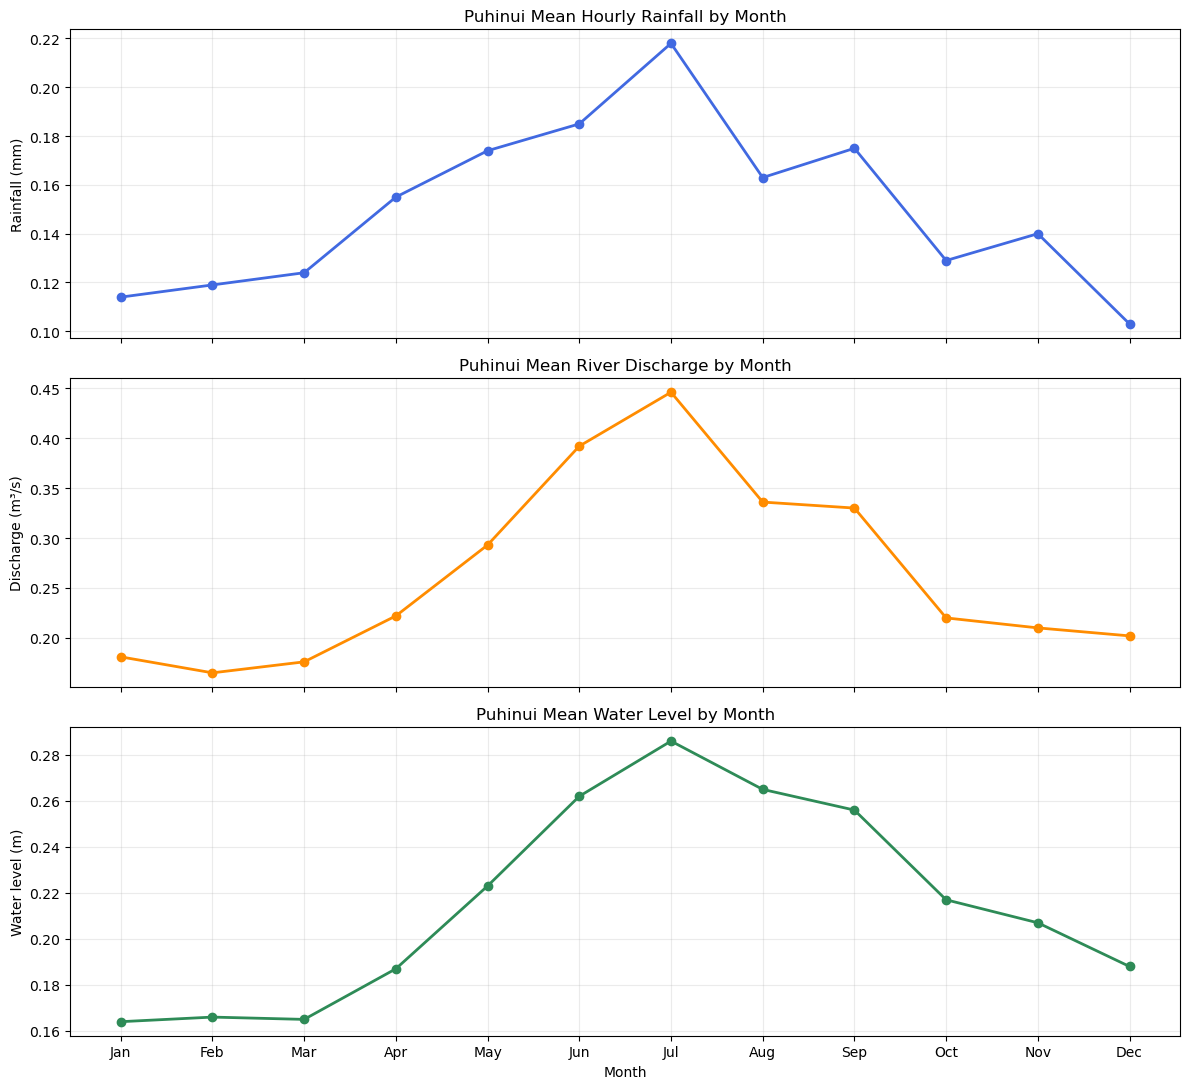

In [22]:
# Code cell 22 - Plot monthly measurement patterns

month_labels = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

fig, axes = plt.subplots(
    3,
    1,
    figsize=(12, 11),
    sharex=True
)

axes[0].plot(
    monthly_patterns.index,
    monthly_patterns["rainfall_mm"],
    marker="o",
    color="royalblue",
    linewidth=2
)

axes[0].set_title(
    "Puhinui Mean Hourly Rainfall by Month"
)
axes[0].set_ylabel(
    "Rainfall (mm)"
)

axes[1].plot(
    monthly_patterns.index,
    monthly_patterns["discharge_m3s"],
    marker="o",
    color="darkorange",
    linewidth=2
)

axes[1].set_title(
    "Puhinui Mean River Discharge by Month"
)
axes[1].set_ylabel(
    "Discharge (m³/s)"
)

axes[2].plot(
    monthly_patterns.index,
    monthly_patterns["water_level_m"],
    marker="o",
    color="seagreen",
    linewidth=2
)

axes[2].set_title(
    "Puhinui Mean Water Level by Month"
)
axes[2].set_ylabel(
    "Water level (m)"
)
axes[2].set_xlabel(
    "Month"
)

axes[2].set_xticks(
    range(1, 13)
)
axes[2].set_xticklabels(
    month_labels
)

for axis in axes:
    axis.grid(
        alpha=0.25
    )

plt.tight_layout()
plt.show()

## 6. Flood-Risk Target Definition and Chronological Data Splitting

Flood risk is defined using an extreme water-level threshold calculated only from the training period. An observation is classified as flood risk when the maximum water level during the following 24 hours reaches or exceeds this threshold.

The dataset is divided chronologically into 70% training, 15% validation, and 15% testing periods. The test period remains completely unseen during model training, model selection, and probability-threshold selection.

In [23]:
# Code cell 23 - Define chronological train, validation and test periods

model_data = (
    puhinui_preprocessed
    .sort_values("timestamp")
    .reset_index(drop=True)
    .copy()
)

total_rows = len(model_data)

train_end_position = int(
    total_rows * 0.70
)

validation_end_position = int(
    total_rows * 0.85
)

model_data["period"] = "Test"

model_data.loc[
    :train_end_position - 1,
    "period"
] = "Training"

model_data.loc[
    train_end_position:validation_end_position - 1,
    "period"
] = "Validation"

period_boundaries = (
    model_data
    .groupby(
        "period",
        sort=False
    )
    .agg(
        rows=("timestamp", "size"),
        beginning=("timestamp", "min"),
        ending=("timestamp", "max")
    )
)

print(
    "Full period:"
)
print(
    model_data["timestamp"].min(),
    "to",
    model_data["timestamp"].max()
)

display(period_boundaries)

Full period:
2015-01-01 01:00:00 to 2026-01-01 00:00:00


,rows,beginning,ending
period,,,
Training,67502,2015-01-01 01:00:00,2022-09-13 14:00:00
Validation,14465,2022-09-13 15:00:00,2024-05-08 07:00:00
Test,14465,2024-05-08 08:00:00,2026-01-01 00:00:00


In [24]:
# Code cell 24 - Calculate training-only high-water threshold

training_water_levels = model_data.loc[
    (
        model_data["period"] == "Training"
    )
    & model_data["water_level_m"].notna(),
    "water_level_m"
]

water_level_threshold = training_water_levels.quantile(
    0.995
)

print(
    "Training observations used for threshold:",
    len(training_water_levels)
)

print(
    "Training-only 99.5th percentile "
    f"water-level threshold: "
    f"{water_level_threshold:.3f} m"
)

Training observations used for threshold: 66975
Training-only 99.5th percentile water-level threshold: 0.865 m


In [25]:
# Code cell 25 - Create the next-24-hour flood-risk target

future_water_level = model_data[
    "water_level_m"
].shift(-1)

model_data[
    "future_max_water_level_24h"
] = (
    future_water_level
    .iloc[::-1]
    .rolling(
        window=24,
        min_periods=1
    )
    .max()
    .iloc[::-1]
)

# A target is available only when the complete 24-hour
# prediction horizon remains inside the same data period.
model_data[
    "target_available"
] = (
    model_data["period"]
    .eq(
        model_data["period"].shift(-24)
    )
    & model_data[
        "future_max_water_level_24h"
    ].notna()
)

model_data[
    "flood_risk_next_24h"
] = np.nan

model_data.loc[
    model_data["target_available"],
    "flood_risk_next_24h"
] = (
    model_data.loc[
        model_data["target_available"],
        "future_max_water_level_24h"
    ]
    >= water_level_threshold
).astype(int)

print(
    "Model-data shape:",
    model_data.shape
)

display(
    model_data[
        [
            "timestamp",
            "water_level_m",
            "future_max_water_level_24h",
            "target_available",
            "flood_risk_next_24h"
        ]
    ].tail(30)
)

Model-data shape: (96432, 19)


,timestamp,water_level_m,future_max_water_level_24h,target_available,flood_risk_next_24h
96402,2025-12-30 19:00:00,0.243,0.710,True,0.000
96403,2025-12-30 20:00:00,0.241,0.710,True,0.000
96404,2025-12-30 21:00:00,0.233,0.710,True,0.000
96405,2025-12-30 22:00:00,0.222,0.710,True,0.000
96406,2025-12-30 23:00:00,0.222,0.710,True,0.000
96407,2025-12-31 00:00:00,0.212,0.710,True,0.000
96408,2025-12-31 01:00:00,0.201,0.710,False,NaN
96409,2025-12-31 02:00:00,0.192,0.710,False,NaN
96410,2025-12-31 03:00:00,0.187,0.710,False,NaN
96411,2025-12-31 04:00:00,0.249,0.710,False,NaN


In [26]:
# Code cell 26 - Summarise flood-risk target distribution

target_distribution = (
    model_data
    .groupby(
        "period",
        sort=False
    )
    .agg(
        eligible_rows_before_feature_removal=(
            "target_available",
            "sum"
        ),
        positive_target_rows=(
            "flood_risk_next_24h",
            "sum"
        )
    )
)

target_distribution[
    "positive_target_rows"
] = target_distribution[
    "positive_target_rows"
].astype(int)

target_distribution[
    "positive_percentage"
] = (
    target_distribution[
        "positive_target_rows"
    ]
    / target_distribution[
        "eligible_rows_before_feature_removal"
    ]
    * 100
).round(3)

display(target_distribution)

,eligible_rows_before_feature_removal,positive_target_rows,positive_percentage
period,,,
Training,67101,1752,2.611
Validation,14441,488,3.379
Test,14441,567,3.926


## 7. Feature Engineering

Predictive features are created only from information available at or before each timestamp. These include current measurements, historical lag values, accumulated rainfall, recent river changes, and cyclical time features.

No future measurements or target-derived values are included as model inputs. Rows with unavailable engineered features are removed only after all features have been generated.

In [27]:
# Code cell 27 - Engineer time-series predictor features

feature_data = model_data.copy()

# Accumulated rainfall features
rainfall_windows = [
    3,
    6,
    12,
    24,
    48
]

for window in rainfall_windows:
    feature_data[
        f"rainfall_sum_{window}h"
    ] = (
        feature_data["rainfall_mm"]
        .rolling(
            window=window,
            min_periods=window
        )
        .sum()
    )

# Historical lag features
lag_hours = [
    1,
    3,
    6,
    12,
    24,
    48
]

lag_variables = [
    "rainfall_mm",
    "discharge_m3s",
    "water_level_m"
]

for variable in lag_variables:
    for lag in lag_hours:
        feature_data[
            f"{variable.replace('_mm', '').replace('_m3s', '').replace('_m', '')}_lag_{lag}h"
        ] = feature_data[
            variable
        ].shift(lag)

# Recent discharge and water-level changes
change_hours = [
    1,
    6,
    24
]

for variable in [
    "discharge_m3s",
    "water_level_m"
]:
    feature_prefix = (
        variable
        .replace("_m3s", "")
        .replace("_m", "")
    )

    for change in change_hours:
        feature_data[
            f"{feature_prefix}_change_{change}h"
        ] = (
            feature_data[variable]
            - feature_data[
                variable
            ].shift(change)
        )

# Cyclical calendar features
feature_data[
    "month_sin"
] = np.sin(
    2
    * np.pi
    * feature_data["timestamp"].dt.month
    / 12
)

feature_data[
    "month_cos"
] = np.cos(
    2
    * np.pi
    * feature_data["timestamp"].dt.month
    / 12
)

feature_data[
    "hour_sin"
] = np.sin(
    2
    * np.pi
    * feature_data["timestamp"].dt.hour
    / 24
)

feature_data[
    "hour_cos"
] = np.cos(
    2
    * np.pi
    * feature_data["timestamp"].dt.hour
    / 24
)

model_features = [
    "rainfall_mm",
    "discharge_m3s",
    "water_level_m",

    "rainfall_sum_3h",
    "rainfall_sum_6h",
    "rainfall_sum_12h",
    "rainfall_sum_24h",
    "rainfall_sum_48h",

    *[
        f"{variable}_lag_{lag}h"
        for variable in [
            "rainfall",
            "discharge",
            "water_level"
        ]
        for lag in lag_hours
    ],

    *[
        f"{variable}_change_{change}h"
        for variable in [
            "discharge",
            "water_level"
        ]
        for change in change_hours
    ],

    "month_sin",
    "month_cos",
    "hour_sin",
    "hour_cos"
]

missing_feature_names = [
    feature
    for feature in model_features
    if feature not in feature_data.columns
]

print(
    "Feature-data shape:",
    feature_data.shape
)

print(
    "Number of model features:",
    len(model_features)
)

print(
    "Missing feature names:",
    missing_feature_names
)

Feature-data shape: (96432, 52)
Number of model features: 36
Missing feature names: []


In [28]:
# Code cell 28 - Remove rows without complete targets or features

rows_before_modelling_filters = len(
    feature_data
)

complete_feature_rows = feature_data[
    model_features
].notna().all(axis=1)

modelling_mask = (
    feature_data["target_available"]
    & complete_feature_rows
    & feature_data[
        "flood_risk_next_24h"
    ].notna()
)

modelling_dataset = feature_data.loc[
    modelling_mask,
    [
        "timestamp",
        "period",
        *model_features,
        "flood_risk_next_24h"
    ]
].copy()

modelling_dataset[
    "flood_risk_next_24h"
] = modelling_dataset[
    "flood_risk_next_24h"
].astype(int)

rows_removed = (
    rows_before_modelling_filters
    - len(modelling_dataset)
)

print(
    "Rows before modelling filters:",
    rows_before_modelling_filters
)

print(
    "Rows removed:",
    rows_removed
)

print(
    "Final modelling rows:",
    len(modelling_dataset)
)

print(
    "Modelling-dataset shape:",
    modelling_dataset.shape
)

print(
    "Remaining missing values:",
    modelling_dataset.isna().sum().sum()
)

Rows before modelling filters: 96432
Rows removed: 8199
Final modelling rows: 88233
Modelling-dataset shape: (88233, 39)
Remaining missing values: 0


In [29]:
# Code cell 29 - Audit final modelling rows by period

final_period_summary = (
    modelling_dataset
    .groupby(
        "period",
        sort=False
    )
    .agg(
        rows=("timestamp", "size"),
        beginning=("timestamp", "min"),
        ending=("timestamp", "max"),
        positive_rows=(
            "flood_risk_next_24h",
            "sum"
        )
    )
)

final_period_summary[
    "positive_percentage"
] = (
    final_period_summary[
        "positive_rows"
    ]
    / final_period_summary[
        "rows"
    ]
    * 100
).round(3)

display(final_period_summary)

,rows,beginning,ending,positive_rows,positive_percentage
period,,,,,
Training,59545,2015-01-03 01:00:00,2022-09-12 14:00:00,1406,2.361
Validation,14265,2022-09-13 15:00:00,2024-05-07 07:00:00,457,3.204
Test,14423,2024-05-08 08:00:00,2025-12-31 00:00:00,567,3.931


## 8. Model Development

Random Forest and XGBoost classifiers are trained using the chronological training period. Model selection and probability-threshold optimisation are performed using only the validation period.

Because flood-risk observations are rare, evaluation focuses on positive-class precision, recall, F1-score, F2-score, ROC-AUC and PR-AUC rather than accuracy alone. The untouched test period is used only once after the final model and probability threshold have been selected.

In [30]:
# Code cell 30 - Create training, validation and test datasets

training_data = modelling_dataset.loc[
    modelling_dataset["period"] == "Training"
].copy()

validation_data = modelling_dataset.loc[
    modelling_dataset["period"] == "Validation"
].copy()

test_data = modelling_dataset.loc[
    modelling_dataset["period"] == "Test"
].copy()

X_train = training_data[
    model_features
].copy()

y_train = training_data[
    "flood_risk_next_24h"
].copy()

X_validation = validation_data[
    model_features
].copy()

y_validation = validation_data[
    "flood_risk_next_24h"
].copy()

X_test = test_data[
    model_features
].copy()

y_test = test_data[
    "flood_risk_next_24h"
].copy()

print(
    "X_train:",
    X_train.shape
)

print(
    "X_validation:",
    X_validation.shape
)

print(
    "X_test:",
    X_test.shape
)

print(
    "\nTraining target distribution:"
)

display(
    y_train
    .value_counts()
    .sort_index()
    .rename("rows")
    .to_frame()
)

print(
    "Training positive percentage:",
    round(
        y_train.mean() * 100,
        3
    )
)

print(
    "Validation positive percentage:",
    round(
        y_validation.mean() * 100,
        3
    )
)

print(
    "Test positive percentage:",
    round(
        y_test.mean() * 100,
        3
    )
)

X_train: (59545, 36)
X_validation: (14265, 36)
X_test: (14423, 36)

Training target distribution:


,rows
flood_risk_next_24h,
0,58139
1,1406


Training positive percentage: 2.361
Validation positive percentage: 3.204
Test positive percentage: 3.931


In [31]:
# Code cell 31 - Train the Random Forest classifier

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score
)

random_forest_model = RandomForestClassifier(
    n_estimators=500,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(
    X_train,
    y_train
)

random_forest_validation_probability = (
    random_forest_model.predict_proba(
        X_validation
    )[:, 1]
)

print(
    "Random Forest training complete."
)

Random Forest training complete.


In [32]:
# Code cell 32 - Evaluate Random Forest on validation data

default_probability_threshold = 0.50

random_forest_validation_prediction = (
    random_forest_validation_probability
    >= default_probability_threshold
).astype(int)

random_forest_validation_confusion = confusion_matrix(
    y_validation,
    random_forest_validation_prediction
)

random_forest_validation_roc_auc = roc_auc_score(
    y_validation,
    random_forest_validation_probability
)

random_forest_validation_pr_auc = average_precision_score(
    y_validation,
    random_forest_validation_probability
)

print(
    "RANDOM FOREST - VALIDATION RESULTS"
)

print(
    f"Probability threshold: "
    f"{default_probability_threshold:.2f}"
)

print(
    "\nConfusion matrix:"
)

print(
    random_forest_validation_confusion
)

print(
    "\nClassification report:"
)

print(
    classification_report(
        y_validation,
        random_forest_validation_prediction,
        digits=4,
        zero_division=0
    )
)

print(
    "ROC-AUC:",
    round(
        random_forest_validation_roc_auc,
        4
    )
)

print(
    "PR-AUC:",
    round(
        random_forest_validation_pr_auc,
        4
    )
)

RANDOM FOREST - VALIDATION RESULTS
Probability threshold: 0.50

Confusion matrix:
[[13787    21]
 [  379    78]]

Classification report:
              precision    recall  f1-score   support

           0     0.9732    0.9985    0.9857     13808
           1     0.7879    0.1707    0.2806       457

    accuracy                         0.9720     14265
   macro avg     0.8806    0.5846    0.6331     14265
weighted avg     0.9673    0.9720    0.9631     14265

ROC-AUC: 0.7396
PR-AUC: 0.2657


In [33]:
# Optimise the Random Forest probability threshold on validation data only

validation_thresholds = np.unique(
    np.concatenate((
        [0.0],
        random_forest_validation_probability,
        [1.0]
    ))
)

threshold_results = []

for threshold in validation_thresholds:
    prediction = (
        random_forest_validation_probability >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_validation,
        prediction,
        labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_validation, prediction, zero_division=0
        ),
        "recall": recall_score(
            y_validation, prediction, zero_division=0
        ),
        "f1_score": f1_score(
            y_validation, prediction, zero_division=0
        ),
        "f2_score": fbeta_score(
            y_validation, prediction, beta=2, zero_division=0
        ),
        "true_negatives": tn,
        "false_positives": fp,
        "false_negatives": fn,
        "true_positives": tp
    })

random_forest_threshold_results = pd.DataFrame(threshold_results)

minimum_validation_recall = 0.80

eligible_thresholds = random_forest_threshold_results[
    random_forest_threshold_results["recall"]
    >= minimum_validation_recall
].copy()

if eligible_thresholds.empty:
    raise ValueError(
        "No Random Forest threshold achieved the required validation recall."
    )

best_threshold_row = (
    eligible_thresholds
    .sort_values(
        ["f2_score", "precision", "threshold"],
        ascending=[False, False, False]
    )
    .iloc[0]
)

random_forest_selected_threshold = float(
    best_threshold_row["threshold"]
)

print("RANDOM FOREST - VALIDATION THRESHOLD SELECTION")
print(f"Minimum required recall: {minimum_validation_recall:.1%}")
print(
    f"Selected probability threshold: "
    f"{random_forest_selected_threshold:.6f}"
)

display(
    best_threshold_row.to_frame(name="selected_value")
)

RANDOM FOREST - VALIDATION THRESHOLD SELECTION
Minimum required recall: 80.0%
Selected probability threshold: 0.003955


,selected_value
threshold,0.004
precision,0.046
recall,0.812
f1_score,0.087
f2_score,0.187
true_negatives,6069.000
false_positives,7739.000
false_negatives,86.000
true_positives,371.000


In [34]:
# Compare practical Random Forest threshold options on validation data

best_unrestricted_f2 = (
    random_forest_threshold_results
    .sort_values(
        ["f2_score", "precision", "threshold"],
        ascending=[False, False, False]
    )
    .iloc[0]
)

threshold_comparisons = [{
    "selection_rule": "Maximum F2 without recall constraint",
    **best_unrestricted_f2.to_dict()
}]

for required_recall in [0.50, 0.60, 0.70, 0.80]:
    eligible = random_forest_threshold_results[
        random_forest_threshold_results["recall"] >= required_recall
    ]

    if not eligible.empty:
        best_candidate = (
            eligible
            .sort_values(
                ["f2_score", "precision", "threshold"],
                ascending=[False, False, False]
            )
            .iloc[0]
        )

        threshold_comparisons.append({
            "selection_rule": f"Maximum F2 with recall >= {required_recall:.0%}",
            **best_candidate.to_dict()
        })

random_forest_threshold_comparison = pd.DataFrame(
    threshold_comparisons
)

comparison_columns = [
    "selection_rule",
    "threshold",
    "precision",
    "recall",
    "f1_score",
    "f2_score",
    "true_positives",
    "false_negatives",
    "false_positives",
    "true_negatives"
]

display(
    random_forest_threshold_comparison[comparison_columns]
    .round({
        "threshold": 6,
        "precision": 4,
        "recall": 4,
        "f1_score": 4,
        "f2_score": 4
    })
)

,selection_rule,threshold,precision,recall,f1_score,f2_score,true_positives,false_negatives,false_positives,true_negatives
0,Maximum F2 without recall constraint,0.063,0.116,0.477,0.186,0.294,218.000,239.000,1663.000,12145.000
1,Maximum F2 with recall >= 50%,0.055,0.108,0.516,0.178,0.294,236.000,221.000,1955.000,11853.000
2,Maximum F2 with recall >= 60%,0.026,0.072,0.635,0.130,0.249,290.000,167.000,3708.000,10100.000
3,Maximum F2 with recall >= 70%,0.017,0.063,0.700,0.116,0.232,320.000,137.000,4761.000,9047.000
4,Maximum F2 with recall >= 80%,0.004,0.046,0.812,0.087,0.187,371.000,86.000,7739.000,6069.000


In [35]:
# Finalise the Random Forest threshold using maximum validation F2

random_forest_selected_threshold = float(
    best_unrestricted_f2["threshold"]
)

random_forest_validation_prediction_selected = (
    random_forest_validation_probability
    >= random_forest_selected_threshold
).astype(int)

random_forest_validation_confusion_selected = confusion_matrix(
    y_validation,
    random_forest_validation_prediction_selected
)

print("RANDOM FOREST - SELECTED VALIDATION THRESHOLD")
print(
    f"Selected probability threshold: "
    f"{random_forest_selected_threshold:.6f}"
)

print("\nConfusion matrix:")
print(random_forest_validation_confusion_selected)

print("\nClassification report:")
print(
    classification_report(
        y_validation,
        random_forest_validation_prediction_selected,
        digits=4,
        zero_division=0
    )
)

print(
    "F2-score:",
    round(
        fbeta_score(
            y_validation,
            random_forest_validation_prediction_selected,
            beta=2,
            zero_division=0
        ),
        4
    )
)

print("ROC-AUC:", round(random_forest_validation_roc_auc, 4))
print("PR-AUC:", round(random_forest_validation_pr_auc, 4))

RANDOM FOREST - SELECTED VALIDATION THRESHOLD
Selected probability threshold: 0.063471

Confusion matrix:
[[12145  1663]
 [  239   218]]

Classification report:
              precision    recall  f1-score   support

           0     0.9807    0.8796    0.9274     13808
           1     0.1159    0.4770    0.1865       457

    accuracy                         0.8667     14265
   macro avg     0.5483    0.6783    0.5569     14265
weighted avg     0.9530    0.8667    0.9036     14265

F2-score: 0.2939
ROC-AUC: 0.7396
PR-AUC: 0.2657


In [36]:
# Evaluate Random Forest validation performance at the event level

random_forest_validation_events = (
    validation_data[["timestamp"]]
    .copy()
    .reset_index(drop=True)
)

random_forest_validation_events["actual_risk"] = (
    np.asarray(y_validation).astype(int)
)

random_forest_validation_events["predicted_risk"] = (
    random_forest_validation_prediction_selected
)

random_forest_validation_events["risk_probability"] = (
    random_forest_validation_probability
)

random_forest_validation_events = (
    random_forest_validation_events
    .sort_values("timestamp")
    .reset_index(drop=True)
)

previous_actual = (
    random_forest_validation_events["actual_risk"]
    .shift(fill_value=0)
)

previous_timestamp = (
    random_forest_validation_events["timestamp"].shift()
)

continuous_from_previous_hour = (
    random_forest_validation_events["timestamp"]
    .sub(previous_timestamp)
    .eq(pd.Timedelta(hours=1))
)

event_start = (
    random_forest_validation_events["actual_risk"].eq(1)
    & (
        previous_actual.ne(1)
        | ~continuous_from_previous_hour
    )
)

random_forest_validation_events["event_id"] = event_start.cumsum()

actual_validation_risk_rows = (
    random_forest_validation_events[
        random_forest_validation_events["actual_risk"].eq(1)
    ]
    .copy()
)

validation_event_results = (
    actual_validation_risk_rows
    .groupby("event_id")
    .agg(
        event_start=("timestamp", "min"),
        event_end=("timestamp", "max"),
        event_duration_hours=("actual_risk", "size"),
        detected_hours=("predicted_risk", "sum"),
        maximum_risk_score=("risk_probability", "max"),
        mean_risk_score=("risk_probability", "mean")
    )
)

validation_event_results["event_detected"] = (
    validation_event_results["detected_hours"] > 0
)

validation_event_results["hourly_detection_percentage"] = (
    100
    * validation_event_results["detected_hours"]
    / validation_event_results["event_duration_hours"]
)

total_validation_events = len(validation_event_results)

detected_validation_events = int(
    validation_event_results["event_detected"].sum()
)

missed_validation_events = (
    total_validation_events - detected_validation_events
)

validation_event_recall = (
    detected_validation_events / total_validation_events
    if total_validation_events > 0
    else np.nan
)

print("RANDOM FOREST - VALIDATION EVENT-LEVEL RESULTS")
print("Total flood-risk episodes:", total_validation_events)
print("Detected episodes:", detected_validation_events)
print("Completely missed episodes:", missed_validation_events)
print("Event-level recall:", round(validation_event_recall, 4))

display(
    validation_event_results
    .sort_values(
        ["event_detected", "event_start"],
        ascending=[True, True]
    )
    .round(3)
)

RANDOM FOREST - VALIDATION EVENT-LEVEL RESULTS
Total flood-risk episodes: 22
Detected episodes: 20
Completely missed episodes: 2
Event-level recall: 0.9091


,event_start,event_end,event_duration_hours,detected_hours,maximum_risk_score,mean_risk_score,event_detected,hourly_detection_percentage
event_id,,,,,,,,
13,2023-04-02 12:00:00,2023-04-03 09:00:00,22,0,0.029,0.004,False,0.000
21,2023-08-31 12:00:00,2023-08-31 12:00:00,1,0,0.010,0.010,False,0.000
1,2022-09-30 16:00:00,2022-10-01 16:00:00,25,15,0.721,0.138,True,60.000
2,2022-10-29 12:00:00,2022-10-30 13:00:00,26,20,0.838,0.239,True,76.923
3,2022-12-09 17:00:00,2022-12-10 18:00:00,26,14,0.892,0.138,True,53.846
4,2023-01-26 09:00:00,2023-01-27 07:00:00,23,3,0.520,0.035,True,13.043
5,2023-01-27 10:00:00,2023-01-27 10:00:00,1,1,0.892,0.892,True,100.000
6,2023-01-27 12:00:00,2023-01-27 13:00:00,2,2,0.903,0.897,True,100.000
7,2023-01-27 15:00:00,2023-01-27 19:00:00,5,5,0.921,0.886,True,100.000


In [37]:
# Final Random Forest evaluation on the untouched test set

random_forest_test_probability = (
    random_forest_model.predict_proba(X_test)[:, 1]
)

random_forest_test_prediction = (
    random_forest_test_probability
    >= random_forest_selected_threshold
).astype(int)

random_forest_test_confusion = confusion_matrix(
    y_test,
    random_forest_test_prediction
)

random_forest_test_roc_auc = roc_auc_score(
    y_test,
    random_forest_test_probability
)

random_forest_test_pr_auc = average_precision_score(
    y_test,
    random_forest_test_probability
)

random_forest_test_f2 = fbeta_score(
    y_test,
    random_forest_test_prediction,
    beta=2,
    zero_division=0
)

print("RANDOM FOREST - FINAL TEST RESULTS")
print(
    f"Locked probability threshold: "
    f"{random_forest_selected_threshold:.6f}"
)

print("\nConfusion matrix:")
print(random_forest_test_confusion)

print("\nClassification report:")
print(
    classification_report(
        y_test,
        random_forest_test_prediction,
        digits=4,
        zero_division=0
    )
)

print("F2-score:", round(random_forest_test_f2, 4))
print("ROC-AUC:", round(random_forest_test_roc_auc, 4))
print("PR-AUC:", round(random_forest_test_pr_auc, 4))

RANDOM FOREST - FINAL TEST RESULTS
Locked probability threshold: 0.063471

Confusion matrix:
[[12252  1604]
 [  306   261]]

Classification report:
              precision    recall  f1-score   support

           0     0.9756    0.8842    0.9277     13856
           1     0.1399    0.4603    0.2146       567

    accuracy                         0.8676     14423
   macro avg     0.5578    0.6723    0.5712     14423
weighted avg     0.9428    0.8676    0.8997     14423

F2-score: 0.3158
ROC-AUC: 0.7389
PR-AUC: 0.2787


In [38]:
# Evaluate final Random Forest test performance at the event level

random_forest_test_events = (
    test_data[["timestamp"]]
    .copy()
    .reset_index(drop=True)
)

random_forest_test_events["actual_risk"] = (
    np.asarray(y_test).astype(int)
)

random_forest_test_events["predicted_risk"] = (
    random_forest_test_prediction
)

random_forest_test_events["risk_probability"] = (
    random_forest_test_probability
)

random_forest_test_events = (
    random_forest_test_events
    .sort_values("timestamp")
    .reset_index(drop=True)
)

previous_actual = (
    random_forest_test_events["actual_risk"]
    .shift(fill_value=0)
)

previous_timestamp = (
    random_forest_test_events["timestamp"].shift()
)

continuous_from_previous_hour = (
    random_forest_test_events["timestamp"]
    .sub(previous_timestamp)
    .eq(pd.Timedelta(hours=1))
)

event_start = (
    random_forest_test_events["actual_risk"].eq(1)
    & (
        previous_actual.ne(1)
        | ~continuous_from_previous_hour
    )
)

random_forest_test_events["event_id"] = event_start.cumsum()

actual_test_risk_rows = (
    random_forest_test_events[
        random_forest_test_events["actual_risk"].eq(1)
    ]
    .copy()
)

test_event_results = (
    actual_test_risk_rows
    .groupby("event_id")
    .agg(
        event_start=("timestamp", "min"),
        event_end=("timestamp", "max"),
        event_duration_hours=("actual_risk", "size"),
        detected_hours=("predicted_risk", "sum"),
        maximum_risk_score=("risk_probability", "max"),
        mean_risk_score=("risk_probability", "mean")
    )
)

test_event_results["event_detected"] = (
    test_event_results["detected_hours"] > 0
)

test_event_results["hourly_detection_percentage"] = (
    100
    * test_event_results["detected_hours"]
    / test_event_results["event_duration_hours"]
)

total_test_events = len(test_event_results)

detected_test_events = int(
    test_event_results["event_detected"].sum()
)

missed_test_events = total_test_events - detected_test_events

test_event_recall = (
    detected_test_events / total_test_events
    if total_test_events > 0
    else np.nan
)

print("RANDOM FOREST - FINAL TEST EVENT-LEVEL RESULTS")
print("Total flood-risk episodes:", total_test_events)
print("Detected episodes:", detected_test_events)
print("Completely missed episodes:", missed_test_events)
print("Event-level recall:", round(test_event_recall, 4))

display(
    test_event_results
    .sort_values(
        ["event_detected", "event_start"],
        ascending=[True, True]
    )
    .round(3)
)

RANDOM FOREST - FINAL TEST EVENT-LEVEL RESULTS
Total flood-risk episodes: 20
Detected episodes: 20
Completely missed episodes: 0
Event-level recall: 1.0


,event_start,event_end,event_duration_hours,detected_hours,maximum_risk_score,mean_risk_score,event_detected,hourly_detection_percentage
event_id,,,,,,,,
1,2024-05-19 23:00:00,2024-05-21 02:00:00,28,8,0.973,0.181,True,28.571
2,2024-06-13 03:00:00,2024-06-14 13:00:00,35,15,0.968,0.178,True,42.857
3,2024-06-16 00:00:00,2024-06-17 01:00:00,26,11,0.929,0.142,True,42.308
4,2024-06-22 05:00:00,2024-06-23 06:00:00,26,8,0.997,0.175,True,30.769
5,2024-08-31 02:00:00,2024-09-01 06:00:00,29,16,1.000,0.214,True,55.172
6,2024-10-02 03:00:00,2024-10-03 05:00:00,27,12,0.973,0.204,True,44.444
7,2024-11-14 14:00:00,2024-11-15 15:00:00,26,10,0.601,0.113,True,38.462
8,2025-02-10 21:00:00,2025-02-11 20:00:00,24,2,0.308,0.022,True,8.333
9,2025-04-18 03:00:00,2025-04-19 05:00:00,27,5,0.984,0.136,True,18.519


In [39]:
# Evaluate Random Forest alert episodes on the test set

previous_prediction = (
    random_forest_test_events["predicted_risk"]
    .shift(fill_value=0)
)

previous_timestamp = (
    random_forest_test_events["timestamp"].shift()
)

continuous_from_previous_hour = (
    random_forest_test_events["timestamp"]
    .sub(previous_timestamp)
    .eq(pd.Timedelta(hours=1))
)

alert_start = (
    random_forest_test_events["predicted_risk"].eq(1)
    & (
        previous_prediction.ne(1)
        | ~continuous_from_previous_hour
    )
)

random_forest_test_events["alert_id"] = alert_start.cumsum()

predicted_test_alert_rows = (
    random_forest_test_events[
        random_forest_test_events["predicted_risk"].eq(1)
    ]
    .copy()
)

test_alert_results = (
    predicted_test_alert_rows
    .groupby("alert_id")
    .agg(
        alert_start=("timestamp", "min"),
        alert_end=("timestamp", "max"),
        alert_duration_hours=("predicted_risk", "size"),
        actual_risk_hours=("actual_risk", "sum"),
        maximum_risk_score=("risk_probability", "max"),
        mean_risk_score=("risk_probability", "mean")
    )
)

test_alert_results["associated_with_risk"] = (
    test_alert_results["actual_risk_hours"] > 0
)

total_test_alerts = len(test_alert_results)

associated_test_alerts = int(
    test_alert_results["associated_with_risk"].sum()
)

false_test_alerts = (
    total_test_alerts - associated_test_alerts
)

test_alert_episode_precision = (
    associated_test_alerts / total_test_alerts
    if total_test_alerts > 0
    else np.nan
)

print("RANDOM FOREST - TEST ALERT-EPISODE RESULTS")
print("Total alert episodes:", total_test_alerts)
print(
    "Alert episodes overlapping a risk period:",
    associated_test_alerts
)
print(
    "Alert episodes with no risk-period overlap:",
    false_test_alerts
)
print(
    "Alert-episode precision:",
    round(test_alert_episode_precision, 4)
)

print("\nAlert-duration summary:")
display(
    test_alert_results
    .groupby("associated_with_risk")["alert_duration_hours"]
    .agg(["count", "mean", "median", "max"])
    .round(3)
)

print("\nLongest false-alert episodes:")
display(
    test_alert_results[
        ~test_alert_results["associated_with_risk"]
    ]
    .sort_values(
        "alert_duration_hours",
        ascending=False
    )
    .head(15)
    .round(3)
)

RANDOM FOREST - TEST ALERT-EPISODE RESULTS
Total alert episodes: 509
Alert episodes overlapping a risk period: 46
Alert episodes with no risk-period overlap: 463
Alert-episode precision: 0.0904

Alert-duration summary:


,count,mean,median,max
associated_with_risk,,,,
False,463,3.374,2.000,24
True,46,6.587,5.000,25



Longest false-alert episodes:


,alert_start,alert_end,alert_duration_hours,actual_risk_hours,maximum_risk_score,mean_risk_score,associated_with_risk
alert_id,,,,,,,
240,2025-04-05 09:00:00,2025-04-06 08:00:00,24,0,0.289,0.148,False
283,2025-05-26 15:00:00,2025-05-27 12:00:00,22,0,0.647,0.278,False
467,2025-10-27 16:00:00,2025-10-28 13:00:00,22,0,0.608,0.222,False
39,2024-06-24 07:00:00,2024-06-25 04:00:00,22,0,0.266,0.149,False
239,2025-04-04 01:00:00,2025-04-04 22:00:00,22,0,0.620,0.267,False
103,2024-08-17 13:00:00,2024-08-18 07:00:00,19,0,0.708,0.295,False
342,2025-07-26 13:00:00,2025-07-27 07:00:00,19,0,0.531,0.184,False
28,2024-06-09 16:00:00,2024-06-10 09:00:00,18,0,0.560,0.243,False
492,2025-12-01 00:00:00,2025-12-01 17:00:00,18,0,0.230,0.126,False


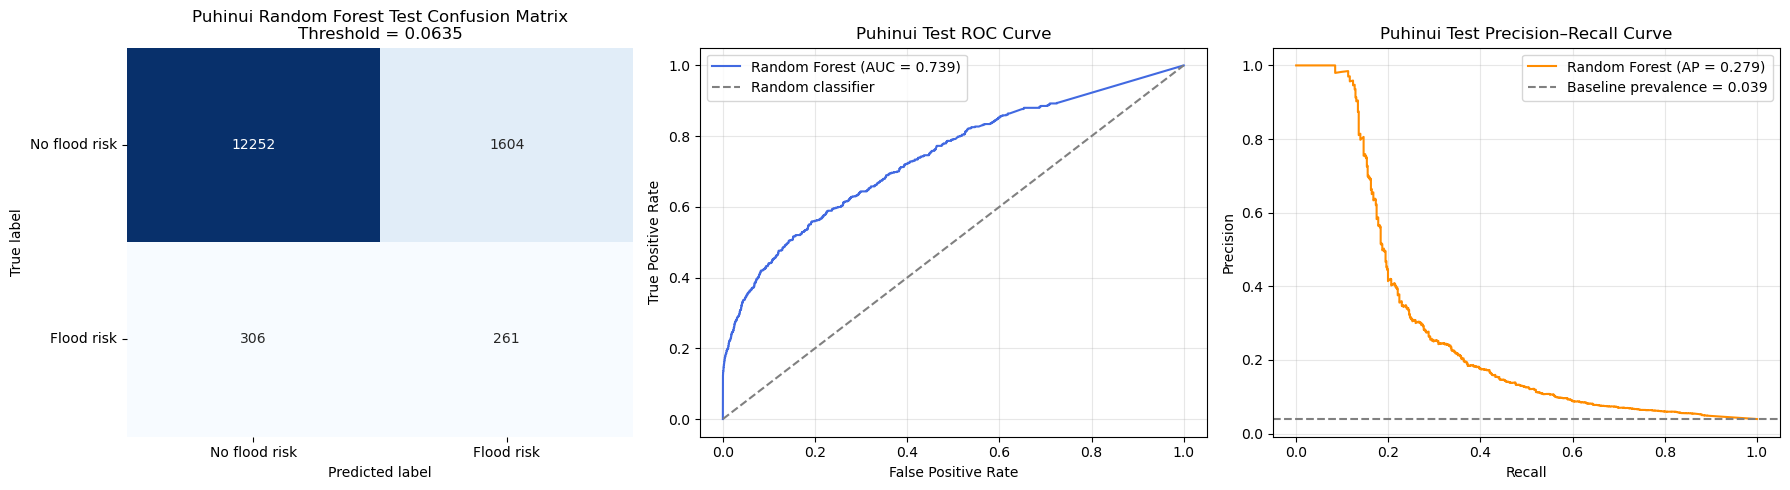

In [40]:
# Plot final Random Forest test evaluation

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    roc_curve,
    precision_recall_curve
)

false_positive_rate, true_positive_rate, _ = roc_curve(
    y_test,
    random_forest_test_probability
)

test_precision_curve, test_recall_curve, _ = (
    precision_recall_curve(
        y_test,
        random_forest_test_probability
    )
)

test_positive_prevalence = np.asarray(y_test).mean()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Confusion matrix
sns.heatmap(
    random_forest_test_confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    ax=axes[0]
)

axes[0].set_title(
    "Puhinui Random Forest Test Confusion Matrix\n"
    f"Threshold = {random_forest_selected_threshold:.4f}"
)
axes[0].set_xlabel("Predicted label")
axes[0].set_ylabel("True label")
axes[0].set_xticklabels(["No flood risk", "Flood risk"])
axes[0].set_yticklabels(
    ["No flood risk", "Flood risk"],
    rotation=0
)

# ROC curve
axes[1].plot(
    false_positive_rate,
    true_positive_rate,
    color="royalblue",
    label=(
        f"Random Forest "
        f"(AUC = {random_forest_test_roc_auc:.3f})"
    )
)

axes[1].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="grey",
    label="Random classifier"
)

axes[1].set_title("Puhinui Test ROC Curve")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend()
axes[1].grid(alpha=0.3)

# Precision–recall curve
axes[2].plot(
    test_recall_curve,
    test_precision_curve,
    color="darkorange",
    label=(
        f"Random Forest "
        f"(AP = {random_forest_test_pr_auc:.3f})"
    )
)

axes[2].axhline(
    test_positive_prevalence,
    linestyle="--",
    color="grey",
    label=(
        f"Baseline prevalence = "
        f"{test_positive_prevalence:.3f}"
    )
)

axes[2].set_title("Puhinui Test Precision–Recall Curve")
axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Top 15 Random Forest features:


,feature,importance
0,discharge_m3s,0.064
1,water_level_m,0.057
2,discharge_change_24h,0.053
3,month_cos,0.049
4,rainfall_sum_48h,0.049
5,discharge_lag_48h,0.046
6,water_level_lag_48h,0.045
7,water_level_change_24h,0.045
8,month_sin,0.039
9,water_level_lag_24h,0.036


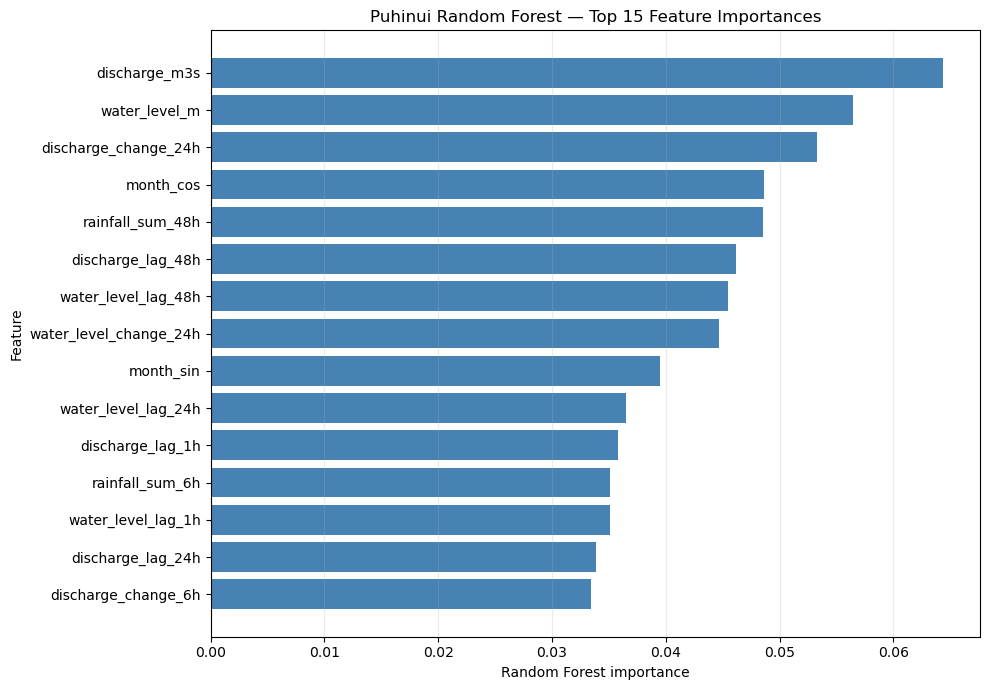

In [41]:
# Calculate and plot Random Forest feature importance

random_forest_feature_importance = (
    pd.DataFrame({
        "feature": X_train.columns.tolist(),
        "importance": random_forest_model.feature_importances_
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

print("Top 15 Random Forest features:")

display(
    random_forest_feature_importance
    .head(15)
    .round(4)
)

top_random_forest_features = (
    random_forest_feature_importance
    .head(15)
    .sort_values("importance", ascending=True)
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_random_forest_features["feature"],
    top_random_forest_features["importance"],
    color="steelblue"
)

plt.title("Puhinui Random Forest — Top 15 Feature Importances")
plt.xlabel("Random Forest importance")
plt.ylabel("Feature")
plt.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

In [42]:
# Create final Random Forest test diagnostic dataset

random_forest_test_diagnostics = pd.DataFrame({
    "timestamp": (
        test_data["timestamp"]
        .reset_index(drop=True)
    ),
    "actual_risk": np.asarray(y_test).astype(int),
    "risk_probability": random_forest_test_probability,
    "predicted_risk": random_forest_test_prediction
})

print(
    "Random Forest test-diagnostic rows:",
    len(random_forest_test_diagnostics)
)

display(
    random_forest_test_diagnostics.head()
)

Random Forest test-diagnostic rows: 14423


,timestamp,actual_risk,risk_probability,predicted_risk
0,2024-05-08 08:00:00,0,0.020,0
1,2024-05-08 09:00:00,0,0.022,0
2,2024-05-08 10:00:00,0,0.026,0
3,2024-05-08 11:00:00,0,0.006,0
4,2024-05-08 12:00:00,0,0.000,0


In [43]:
# Save Puhinui Random Forest outputs

import json
import joblib

puhinui_preprocessed.to_csv(
    "puhinui_preprocessed.csv",
    index=False
)

modelling_dataset.to_csv(
    "puhinui_modelling_dataset.csv",
    index=False
)

random_forest_test_diagnostics.to_csv(
    "puhinui_random_forest_test_predictions.csv",
    index=False
)

test_event_results.to_csv(
    "puhinui_random_forest_test_events.csv",
    index=True
)

test_alert_results.to_csv(
    "puhinui_random_forest_test_alerts.csv",
    index=True
)

random_forest_feature_importance.to_csv(
    "puhinui_random_forest_feature_importance.csv",
    index=False
)

joblib.dump(
    random_forest_model,
    "puhinui_random_forest_model.joblib"
)

random_forest_metadata = {
    "catchment": "Puhinui",
    "target": "flood_risk_next_24h",
    "water_level_risk_threshold_m": float(
        water_level_threshold
    ),
    "probability_threshold": float(
        random_forest_selected_threshold
    ),
    "features": X_train.columns.tolist(),
    "test_roc_auc": float(random_forest_test_roc_auc),
    "test_pr_auc": float(random_forest_test_pr_auc),
    "test_f2_score": float(random_forest_test_f2),
    "test_event_recall": float(test_event_recall),
    "test_alert_episode_precision": float(
        test_alert_episode_precision
    )
}

with open(
    "puhinui_random_forest_metadata.json",
    "w"
) as metadata_file:
    json.dump(
        random_forest_metadata,
        metadata_file,
        indent=4
    )

print("Puhinui Random Forest outputs saved successfully.")

Puhinui Random Forest outputs saved successfully.


## 9. XGBoost Model Development

An XGBoost classifier was trained using the same chronological data partitions and 36 predictor variables as the Random Forest. Class weighting was calculated from the training data to address the substantial imbalance between flood-risk and non-risk observations. Probability-threshold selection was performed exclusively on validation data.

In [44]:
# Train the Puhinui XGBoost classifier

from xgboost import XGBClassifier

training_negative_count = int((y_train == 0).sum())
training_positive_count = int((y_train == 1).sum())

xgboost_scale_positive_weight = (
    training_negative_count / training_positive_count
)

xgboost_model = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    min_child_weight=2,
    subsample=0.80,
    colsample_bytree=0.80,
    scale_pos_weight=xgboost_scale_positive_weight,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgboost_model.fit(
    X_train,
    y_train
)

xgboost_validation_probability = (
    xgboost_model.predict_proba(X_validation)[:, 1]
)

print("XGBoost training complete.")
print(
    "Training scale_pos_weight:",
    round(xgboost_scale_positive_weight, 3)
)

XGBoost training complete.
Training scale_pos_weight: 41.351


In [45]:
# Evaluate XGBoost on validation data at the default threshold

xgboost_default_threshold = 0.50

xgboost_validation_prediction_default = (
    xgboost_validation_probability
    >= xgboost_default_threshold
).astype(int)

xgboost_validation_confusion_default = confusion_matrix(
    y_validation,
    xgboost_validation_prediction_default
)

xgboost_validation_roc_auc = roc_auc_score(
    y_validation,
    xgboost_validation_probability
)

xgboost_validation_pr_auc = average_precision_score(
    y_validation,
    xgboost_validation_probability
)

xgboost_validation_f2_default = fbeta_score(
    y_validation,
    xgboost_validation_prediction_default,
    beta=2,
    zero_division=0
)

print("XGBOOST - VALIDATION RESULTS")
print(f"Probability threshold: {xgboost_default_threshold:.2f}")

print("\nConfusion matrix:")
print(xgboost_validation_confusion_default)

print("\nClassification report:")
print(
    classification_report(
        y_validation,
        xgboost_validation_prediction_default,
        digits=4,
        zero_division=0
    )
)

print(
    "F2-score:",
    round(xgboost_validation_f2_default, 4)
)
print("ROC-AUC:", round(xgboost_validation_roc_auc, 4))
print("PR-AUC:", round(xgboost_validation_pr_auc, 4))

XGBOOST - VALIDATION RESULTS
Probability threshold: 0.50

Confusion matrix:
[[13297   511]
 [  333   124]]

Classification report:
              precision    recall  f1-score   support

           0     0.9756    0.9630    0.9692     13808
           1     0.1953    0.2713    0.2271       457

    accuracy                         0.9408     14265
   macro avg     0.5854    0.6172    0.5982     14265
weighted avg     0.9506    0.9408    0.9455     14265

F2-score: 0.2517
ROC-AUC: 0.6695
PR-AUC: 0.2469


In [46]:
# Select the XGBoost threshold that maximises validation F2

xgboost_validation_thresholds = np.unique(
    np.concatenate((
        [0.0],
        xgboost_validation_probability,
        [1.0]
    ))
)

xgboost_threshold_records = []

for threshold in xgboost_validation_thresholds:
    prediction = (
        xgboost_validation_probability >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_validation,
        prediction,
        labels=[0, 1]
    ).ravel()

    xgboost_threshold_records.append({
        "threshold": threshold,
        "precision": precision_score(
            y_validation,
            prediction,
            zero_division=0
        ),
        "recall": recall_score(
            y_validation,
            prediction,
            zero_division=0
        ),
        "f1_score": f1_score(
            y_validation,
            prediction,
            zero_division=0
        ),
        "f2_score": fbeta_score(
            y_validation,
            prediction,
            beta=2,
            zero_division=0
        ),
        "true_negatives": tn,
        "false_positives": fp,
        "false_negatives": fn,
        "true_positives": tp
    })

xgboost_threshold_results = pd.DataFrame(
    xgboost_threshold_records
)

xgboost_best_threshold_row = (
    xgboost_threshold_results
    .sort_values(
        ["f2_score", "precision", "threshold"],
        ascending=[False, False, False]
    )
    .iloc[0]
)

xgboost_selected_threshold = float(
    xgboost_best_threshold_row["threshold"]
)

print("XGBOOST - VALIDATION THRESHOLD SELECTION")
print(
    f"Selected probability threshold: "
    f"{xgboost_selected_threshold:.6f}"
)

display(
    xgboost_best_threshold_row
    .to_frame(name="selected_value")
    .round(4)
)

XGBOOST - VALIDATION THRESHOLD SELECTION
Selected probability threshold: 0.622692


,selected_value
threshold,0.623
precision,0.312
recall,0.254
f1_score,0.280
f2_score,0.264
true_negatives,13552.000
false_positives,256.000
false_negatives,341.000
true_positives,116.000


In [47]:
# Evaluate XGBoost at the selected validation threshold

xgboost_validation_prediction_selected = (
    xgboost_validation_probability
    >= xgboost_selected_threshold
).astype(int)

print("XGBOOST - SELECTED VALIDATION THRESHOLD")
print(
    f"Selected probability threshold: "
    f"{xgboost_selected_threshold:.6f}"
)

print("\nConfusion matrix:")
print(
    confusion_matrix(
        y_validation,
        xgboost_validation_prediction_selected
    )
)

print("\nClassification report:")
print(
    classification_report(
        y_validation,
        xgboost_validation_prediction_selected,
        digits=4,
        zero_division=0
    )
)

print(
    "F2-score:",
    round(
        fbeta_score(
            y_validation,
            xgboost_validation_prediction_selected,
            beta=2,
            zero_division=0
        ),
        4
    )
)

# Create validation event table
xgboost_validation_events = (
    validation_data[["timestamp"]]
    .copy()
    .reset_index(drop=True)
)

xgboost_validation_events["actual_risk"] = (
    np.asarray(y_validation).astype(int)
)

xgboost_validation_events["predicted_risk"] = (
    xgboost_validation_prediction_selected
)

xgboost_validation_events["risk_probability"] = (
    xgboost_validation_probability
)

previous_actual = (
    xgboost_validation_events["actual_risk"]
    .shift(fill_value=0)
)

previous_timestamp = (
    xgboost_validation_events["timestamp"].shift()
)

continuous_from_previous_hour = (
    xgboost_validation_events["timestamp"]
    .sub(previous_timestamp)
    .eq(pd.Timedelta(hours=1))
)

event_start = (
    xgboost_validation_events["actual_risk"].eq(1)
    & (
        previous_actual.ne(1)
        | ~continuous_from_previous_hour
    )
)

xgboost_validation_events["event_id"] = event_start.cumsum()

xgboost_validation_event_results = (
    xgboost_validation_events[
        xgboost_validation_events["actual_risk"].eq(1)
    ]
    .groupby("event_id")
    .agg(
        event_start=("timestamp", "min"),
        event_end=("timestamp", "max"),
        event_duration_hours=("actual_risk", "size"),
        detected_hours=("predicted_risk", "sum"),
        maximum_risk_score=("risk_probability", "max"),
        mean_risk_score=("risk_probability", "mean")
    )
)

xgboost_validation_event_results["event_detected"] = (
    xgboost_validation_event_results["detected_hours"] > 0
)

xgboost_validation_event_results[
    "hourly_detection_percentage"
] = (
    100
    * xgboost_validation_event_results["detected_hours"]
    / xgboost_validation_event_results["event_duration_hours"]
)

xgboost_total_validation_events = len(
    xgboost_validation_event_results
)

xgboost_detected_validation_events = int(
    xgboost_validation_event_results["event_detected"].sum()
)

xgboost_validation_event_recall = (
    xgboost_detected_validation_events
    / xgboost_total_validation_events
)

print("\nXGBOOST - VALIDATION EVENT-LEVEL RESULTS")
print(
    "Total flood-risk episodes:",
    xgboost_total_validation_events
)
print(
    "Detected episodes:",
    xgboost_detected_validation_events
)
print(
    "Completely missed episodes:",
    xgboost_total_validation_events
    - xgboost_detected_validation_events
)
print(
    "Event-level recall:",
    round(xgboost_validation_event_recall, 4)
)

display(
    xgboost_validation_event_results
    .sort_values(
        ["event_detected", "event_start"],
        ascending=[True, True]
    )
    .round(3)
)

XGBOOST - SELECTED VALIDATION THRESHOLD
Selected probability threshold: 0.622692

Confusion matrix:
[[13552   256]
 [  341   116]]

Classification report:
              precision    recall  f1-score   support

           0     0.9755    0.9815    0.9784     13808
           1     0.3118    0.2538    0.2799       457

    accuracy                         0.9581     14265
   macro avg     0.6436    0.6176    0.6292     14265
weighted avg     0.9542    0.9581    0.9561     14265

F2-score: 0.2636

XGBOOST - VALIDATION EVENT-LEVEL RESULTS
Total flood-risk episodes: 22
Detected episodes: 18
Completely missed episodes: 4
Event-level recall: 0.8182


,event_start,event_end,event_duration_hours,detected_hours,maximum_risk_score,mean_risk_score,event_detected,hourly_detection_percentage
event_id,,,,,,,,
4,2023-01-26 09:00:00,2023-01-27 07:00:00,23,0,0.561,0.034,False,0.000
9,2023-01-28 12:00:00,2023-01-29 07:00:00,20,0,0.072,0.030,False,0.000
13,2023-04-02 12:00:00,2023-04-03 09:00:00,22,0,0.180,0.028,False,0.000
21,2023-08-31 12:00:00,2023-08-31 12:00:00,1,0,0.182,0.182,False,0.000
1,2022-09-30 16:00:00,2022-10-01 16:00:00,25,7,0.872,0.384,True,28.000
2,2022-10-29 12:00:00,2022-10-30 13:00:00,26,11,0.995,0.497,True,42.308
3,2022-12-09 17:00:00,2022-12-10 18:00:00,26,2,0.917,0.159,True,7.692
5,2023-01-27 10:00:00,2023-01-27 10:00:00,1,1,0.973,0.973,True,100.000
6,2023-01-27 12:00:00,2023-01-27 13:00:00,2,2,0.996,0.988,True,100.000


In [48]:
# Evaluate XGBoost on the untouched test period using the locked validation threshold

import numpy as np
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    fbeta_score,
    roc_auc_score,
    average_precision_score
)

# Generate test probabilities
xgboost_test_probability = xgboost_model.predict_proba(X_test)[:, 1]

# Apply the threshold selected exclusively from validation data
xgboost_test_prediction = (
    xgboost_test_probability >= xgboost_selected_threshold
).astype(int)

# Hour-level test metrics
xgboost_test_confusion_matrix = confusion_matrix(
    y_test,
    xgboost_test_prediction
)

xgboost_test_f2 = fbeta_score(
    y_test,
    xgboost_test_prediction,
    beta=2,
    zero_division=0
)

xgboost_test_roc_auc = roc_auc_score(
    y_test,
    xgboost_test_probability
)

xgboost_test_pr_auc = average_precision_score(
    y_test,
    xgboost_test_probability
)

print("XGBOOST - FINAL TEST RESULTS")
print(
    f"Locked probability threshold: "
    f"{xgboost_selected_threshold:.6f}"
)

print("\nConfusion matrix:")
print(xgboost_test_confusion_matrix)

print("\nClassification report:")
print(
    classification_report(
        y_test,
        xgboost_test_prediction,
        digits=4,
        zero_division=0
    )
)

print(f"F2-score: {xgboost_test_f2:.4f}")
print(f"ROC-AUC: {xgboost_test_roc_auc:.4f}")
print(f"PR-AUC: {xgboost_test_pr_auc:.4f}")

XGBOOST - FINAL TEST RESULTS
Locked probability threshold: 0.622692

Confusion matrix:
[[13516   340]
 [  435   132]]

Classification report:
              precision    recall  f1-score   support

           0     0.9688    0.9755    0.9721     13856
           1     0.2797    0.2328    0.2541       567

    accuracy                         0.9463     14423
   macro avg     0.6242    0.6041    0.6131     14423
weighted avg     0.9417    0.9463    0.9439     14423

F2-score: 0.2409
ROC-AUC: 0.7212
PR-AUC: 0.2542


In [49]:
# Evaluate XGBoost final-test performance at the flood-event level

import numpy as np
import pandas as pd

# Create timestamp-level test results
xgboost_test_events = pd.DataFrame({
    "timestamp": pd.to_datetime(test_data["timestamp"]).to_numpy(),
    "actual_risk": np.asarray(y_test).astype(int),
    "risk_probability": xgboost_test_probability,
    "predicted_risk": xgboost_test_prediction
}).sort_values("timestamp").reset_index(drop=True)

# Retain only actual flood-risk hours
actual_event_hours = (
    xgboost_test_events
    .loc[xgboost_test_events["actual_risk"] == 1]
    .copy()
)

# Start a new event when consecutive risk hours are more than one hour apart
actual_event_hours["event_id"] = (
    actual_event_hours["timestamp"]
    .diff()
    .ne(pd.Timedelta(hours=1))
    .cumsum()
)

# Summarise each actual flood-risk event
xgboost_test_event_results = (
    actual_event_hours
    .groupby("event_id")
    .agg(
        event_start=("timestamp", "min"),
        event_end=("timestamp", "max"),
        event_duration_hours=("timestamp", "size"),
        detected_hours=("predicted_risk", "sum"),
        maximum_risk_score=("risk_probability", "max"),
        mean_risk_score=("risk_probability", "mean")
    )
)

xgboost_test_event_results["event_detected"] = (
    xgboost_test_event_results["detected_hours"] > 0
)

xgboost_test_event_results["hourly_detection_percentage"] = (
    100
    * xgboost_test_event_results["detected_hours"]
    / xgboost_test_event_results["event_duration_hours"]
)

# Event-level metrics
xgboost_total_test_events = len(xgboost_test_event_results)

xgboost_detected_test_events = int(
    xgboost_test_event_results["event_detected"].sum()
)

xgboost_missed_test_events = (
    xgboost_total_test_events
    - xgboost_detected_test_events
)

xgboost_test_event_recall = (
    xgboost_detected_test_events
    / xgboost_total_test_events
)

print("XGBOOST - FINAL TEST EVENT-LEVEL RESULTS")
print(f"Total flood-risk episodes: {xgboost_total_test_events}")
print(f"Detected episodes: {xgboost_detected_test_events}")
print(f"Completely missed episodes: {xgboost_missed_test_events}")
print(f"Event-level recall: {xgboost_test_event_recall:.4f}")

# Show missed events first
display(
    xgboost_test_event_results
    .sort_values(
        ["event_detected", "event_start"],
        ascending=[True, True]
    )
    .round(3)
)

XGBOOST - FINAL TEST EVENT-LEVEL RESULTS
Total flood-risk episodes: 20
Detected episodes: 20
Completely missed episodes: 0
Event-level recall: 1.0000


,event_start,event_end,event_duration_hours,detected_hours,maximum_risk_score,mean_risk_score,event_detected,hourly_detection_percentage
event_id,,,,,,,,
1,2024-05-19 23:00:00,2024-05-21 02:00:00,28,6,0.995,0.247,True,21.429
2,2024-06-13 03:00:00,2024-06-14 13:00:00,35,9,0.992,0.372,True,25.714
3,2024-06-16 00:00:00,2024-06-17 01:00:00,26,6,0.997,0.295,True,23.077
4,2024-06-22 05:00:00,2024-06-23 06:00:00,26,6,0.998,0.286,True,23.077
5,2024-08-31 02:00:00,2024-09-01 06:00:00,29,8,0.997,0.373,True,27.586
6,2024-10-02 03:00:00,2024-10-03 05:00:00,27,9,0.999,0.608,True,33.333
7,2024-11-14 14:00:00,2024-11-15 15:00:00,26,2,0.864,0.145,True,7.692
8,2025-02-10 21:00:00,2025-02-11 20:00:00,24,1,0.672,0.038,True,4.167
9,2025-04-18 03:00:00,2025-04-19 05:00:00,27,3,0.996,0.151,True,11.111


In [50]:
# Evaluate XGBoost alert episodes on the final test period

# Start a new alert when predicted-risk hours are not consecutive
xgboost_alert_hours = (
    xgboost_test_events
    .loc[xgboost_test_events["predicted_risk"] == 1]
    .copy()
)

xgboost_alert_hours["alert_id"] = (
    xgboost_alert_hours["timestamp"]
    .diff()
    .ne(pd.Timedelta(hours=1))
    .cumsum()
)

# Summarise each continuous alert episode
xgboost_test_alert_results = (
    xgboost_alert_hours
    .groupby("alert_id")
    .agg(
        alert_start=("timestamp", "min"),
        alert_end=("timestamp", "max"),
        alert_duration_hours=("timestamp", "size"),
        actual_risk_hours=("actual_risk", "sum"),
        maximum_risk_score=("risk_probability", "max"),
        mean_risk_score=("risk_probability", "mean")
    )
)

# An alert is useful if it overlaps at least one actual risk hour
xgboost_test_alert_results["associated_with_risk"] = (
    xgboost_test_alert_results["actual_risk_hours"] > 0
)

xgboost_total_alert_episodes = len(xgboost_test_alert_results)

xgboost_risk_associated_alerts = int(
    xgboost_test_alert_results["associated_with_risk"].sum()
)

xgboost_false_alert_episodes = (
    xgboost_total_alert_episodes
    - xgboost_risk_associated_alerts
)

xgboost_alert_episode_precision = (
    xgboost_risk_associated_alerts
    / xgboost_total_alert_episodes
)

print("XGBOOST - TEST ALERT-EPISODE RESULTS")
print(f"Total alert episodes: {xgboost_total_alert_episodes}")
print(
    "Alert episodes overlapping a risk period: "
    f"{xgboost_risk_associated_alerts}"
)
print(
    "Alert episodes with no risk-period overlap: "
    f"{xgboost_false_alert_episodes}"
)
print(
    "Alert-episode precision: "
    f"{xgboost_alert_episode_precision:.4f}"
)

print("\nAlert-duration summary:")
display(
    xgboost_test_alert_results
    .groupby("associated_with_risk")["alert_duration_hours"]
    .agg(["count", "mean", "median", "max"])
    .round(3)
)

print("\nLongest false-alert episodes:")
display(
    xgboost_test_alert_results
    .loc[~xgboost_test_alert_results["associated_with_risk"]]
    .sort_values(
        ["alert_duration_hours", "maximum_risk_score"],
        ascending=[False, False]
    )
    .head(15)
    .round(3)
)

XGBOOST - TEST ALERT-EPISODE RESULTS
Total alert episodes: 165
Alert episodes overlapping a risk period: 42
Alert episodes with no risk-period overlap: 123
Alert-episode precision: 0.2545

Alert-duration summary:


,count,mean,median,max
associated_with_risk,,,,
False,123,2.715,2.000,15
True,42,3.286,3.000,14



Longest false-alert episodes:


,alert_start,alert_end,alert_duration_hours,actual_risk_hours,maximum_risk_score,mean_risk_score,associated_with_risk
alert_id,,,,,,,
70,2025-03-01 23:00:00,2025-03-02 13:00:00,15,0,0.919,0.773,False
74,2025-03-28 02:00:00,2025-03-28 15:00:00,14,0,0.960,0.880,False
34,2024-08-17 12:00:00,2024-08-17 20:00:00,9,0,0.948,0.865,False
47,2024-09-20 10:00:00,2024-09-20 17:00:00,8,0,0.976,0.778,False
88,2025-05-26 19:00:00,2025-05-27 02:00:00,8,0,0.958,0.880,False
41,2024-09-08 18:00:00,2024-09-09 01:00:00,8,0,0.807,0.730,False
76,2025-04-04 06:00:00,2025-04-04 12:00:00,7,0,0.935,0.835,False
157,2025-10-14 02:00:00,2025-10-14 08:00:00,7,0,0.894,0.750,False
73,2025-03-25 22:00:00,2025-03-26 04:00:00,7,0,0.790,0.773,False


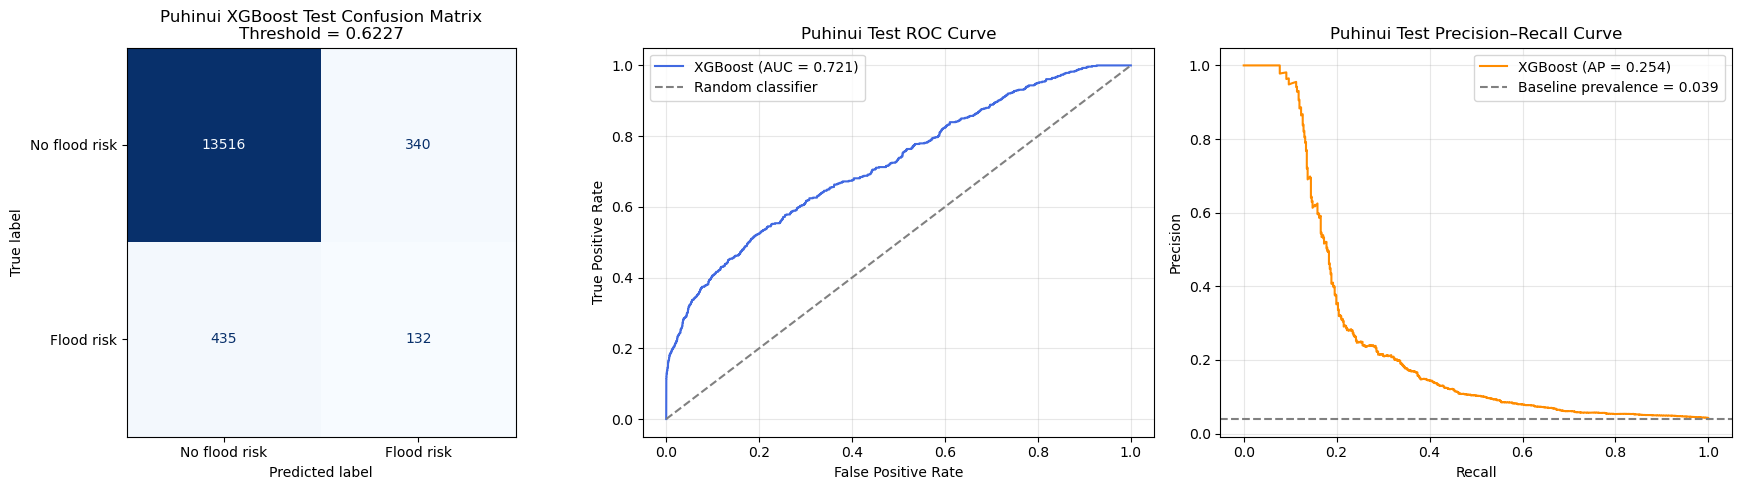

In [51]:
# Plot XGBoost final-test confusion matrix, ROC curve, and PR curve

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve
)

# Curve coordinates
xgboost_test_fpr, xgboost_test_tpr, _ = roc_curve(
    y_test,
    xgboost_test_probability
)

xgboost_test_precision_curve, xgboost_test_recall_curve, _ = (
    precision_recall_curve(
        y_test,
        xgboost_test_probability
    )
)

xgboost_test_baseline = np.asarray(y_test).mean()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix=xgboost_test_confusion_matrix,
    display_labels=["No flood risk", "Flood risk"]
).plot(
    ax=axes[0],
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

axes[0].set_title(
    "Puhinui XGBoost Test Confusion Matrix\n"
    f"Threshold = {xgboost_selected_threshold:.4f}"
)

# ROC curve
axes[1].plot(
    xgboost_test_fpr,
    xgboost_test_tpr,
    color="royalblue",
    label=f"XGBoost (AUC = {xgboost_test_roc_auc:.3f})"
)

axes[1].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="grey",
    label="Random classifier"
)

axes[1].set_title("Puhinui Test ROC Curve")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend()
axes[1].grid(alpha=0.3)

# Precision-recall curve
axes[2].plot(
    xgboost_test_recall_curve,
    xgboost_test_precision_curve,
    color="darkorange",
    label=f"XGBoost (AP = {xgboost_test_pr_auc:.3f})"
)

axes[2].axhline(
    xgboost_test_baseline,
    linestyle="--",
    color="grey",
    label=f"Baseline prevalence = {xgboost_test_baseline:.3f}"
)

axes[2].set_title("Puhinui Test Precision–Recall Curve")
axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Top 15 XGBoost features:


,feature,importance
0,rainfall_sum_6h,0.116
1,water_level_m,0.095
2,discharge_m3s,0.066
3,discharge_change_24h,0.053
4,rainfall_sum_3h,0.037
5,water_level_change_24h,0.036
6,month_cos,0.034
7,water_level_lag_1h,0.034
8,month_sin,0.033
9,rainfall_mm,0.031


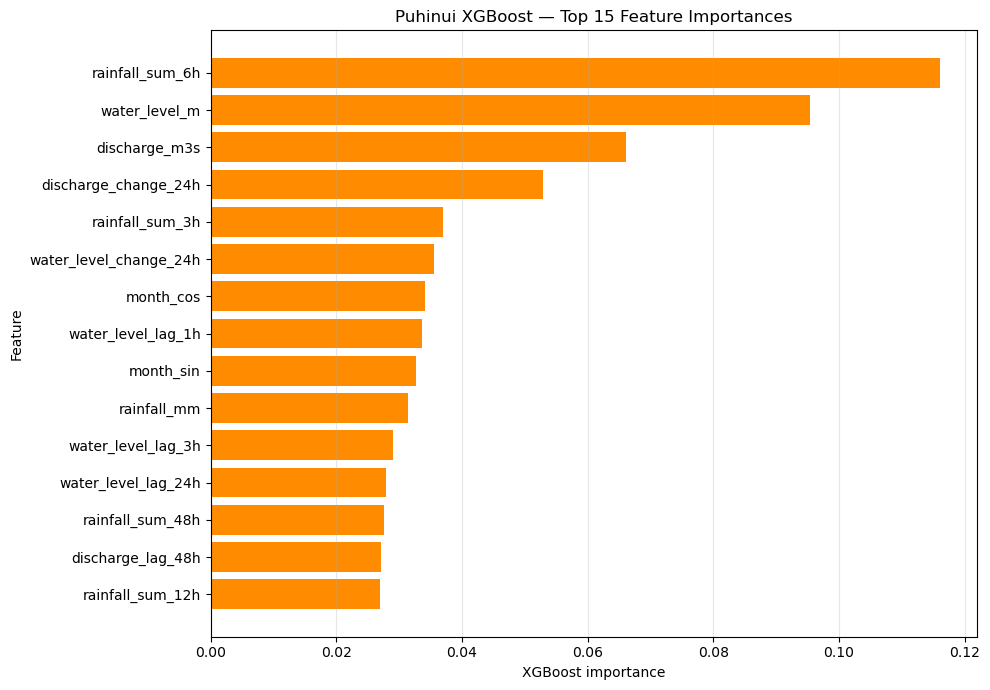

In [52]:
# Calculate and plot XGBoost feature importance

xgboost_feature_importance = (
    pd.DataFrame({
        "feature": X_train.columns,
        "importance": xgboost_model.feature_importances_
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

print("Top 15 XGBoost features:")
display(
    xgboost_feature_importance
    .head(15)
    .round(4)
)

# Plot top 15 features
xgboost_top_features = (
    xgboost_feature_importance
    .head(15)
    .sort_values("importance", ascending=True)
)

plt.figure(figsize=(10, 7))

plt.barh(
    xgboost_top_features["feature"],
    xgboost_top_features["importance"],
    color="darkorange"
)

plt.title("Puhinui XGBoost — Top 15 Feature Importances")
plt.xlabel("XGBoost importance")
plt.ylabel("Feature")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [53]:
# Create the final XGBoost test-diagnostic dataset

xgboost_test_diagnostics = (
    xgboost_test_events[
        [
            "timestamp",
            "actual_risk",
            "risk_probability",
            "predicted_risk"
        ]
    ]
    .copy()
    .reset_index(drop=True)
)

print(
    "XGBoost test-diagnostic rows:",
    len(xgboost_test_diagnostics)
)

display(
    xgboost_test_diagnostics
    .head()
    .round({
        "risk_probability": 3
    })
)

XGBoost test-diagnostic rows: 14423


,timestamp,actual_risk,risk_probability,predicted_risk
0,2024-05-08 08:00:00,0,0.123,0
1,2024-05-08 09:00:00,0,0.111,0
2,2024-05-08 10:00:00,0,0.205,0
3,2024-05-08 11:00:00,0,0.030,0
4,2024-05-08 12:00:00,0,0.001,0


In [54]:
# Save the complete Puhinui XGBoost model package

from pathlib import Path
import json
import joblib
import numpy as np

xgboost_output_directory = Path("puhinui_xgboost_outputs")
xgboost_output_directory.mkdir(exist_ok=True)

# Save tabular outputs
xgboost_test_diagnostics.to_csv(
    xgboost_output_directory /
    "puhinui_xgboost_test_predictions.csv",
    index=False
)

xgboost_test_event_results.reset_index().to_csv(
    xgboost_output_directory /
    "puhinui_xgboost_test_events.csv",
    index=False
)

xgboost_test_alert_results.reset_index().to_csv(
    xgboost_output_directory /
    "puhinui_xgboost_test_alert_episodes.csv",
    index=False
)

xgboost_feature_importance.to_csv(
    xgboost_output_directory /
    "puhinui_xgboost_feature_importance.csv",
    index=False
)

xgboost_threshold_results.to_csv(
    xgboost_output_directory /
    "puhinui_xgboost_validation_threshold_results.csv",
    index=False
)

# Save model in native XGBoost and joblib formats
xgboost_model.save_model(
    xgboost_output_directory /
    "puhinui_xgboost_model.json"
)

joblib.dump(
    xgboost_model,
    xgboost_output_directory /
    "puhinui_xgboost_model.joblib"
)

# Save metadata required for reproducibility and dashboard use
xgboost_metadata = {
    "catchment": "Puhinui",
    "model": "XGBoost classifier",
    "prediction_horizon_hours": 24,
    "water_level_threshold_m": float(water_level_threshold),
    "probability_threshold": float(xgboost_selected_threshold),
    "threshold_selection": (
        "Maximum validation F2-score using exact validation probabilities"
    ),
    "training_rows": int(len(X_train)),
    "validation_rows": int(len(X_validation)),
    "test_rows": int(len(X_test)),
    "number_of_features": int(X_train.shape[1]),
    "feature_names": X_train.columns.tolist(),
    "training_scale_pos_weight": float(
        (np.asarray(y_train) == 0).sum()
        / (np.asarray(y_train) == 1).sum()
    ),
    "test_confusion_matrix": (
        xgboost_test_confusion_matrix.astype(int).tolist()
    ),
    "test_f2_score": float(xgboost_test_f2),
    "test_roc_auc": float(xgboost_test_roc_auc),
    "test_pr_auc": float(xgboost_test_pr_auc),
    "test_total_events": int(xgboost_total_test_events),
    "test_detected_events": int(xgboost_detected_test_events),
    "test_event_recall": float(xgboost_test_event_recall),
    "test_total_alert_episodes": int(xgboost_total_alert_episodes),
    "test_risk_associated_alert_episodes": int(
        xgboost_risk_associated_alerts
    ),
    "test_false_alert_episodes": int(xgboost_false_alert_episodes),
    "test_alert_episode_precision": float(
        xgboost_alert_episode_precision
    )
}

with open(
    xgboost_output_directory /
    "puhinui_xgboost_metadata.json",
    "w",
    encoding="utf-8"
) as metadata_file:
    json.dump(
        xgboost_metadata,
        metadata_file,
        indent=4
    )

print("XGBoost outputs saved successfully:\n")

for saved_file in sorted(xgboost_output_directory.iterdir()):
    print(
        f"{saved_file.name}: "
        f"{saved_file.stat().st_size:,} bytes"
    )

XGBoost outputs saved successfully:

puhinui_xgboost_feature_importance.csv: 1,094 bytes
puhinui_xgboost_metadata.json: 2,104 bytes
puhinui_xgboost_model.joblib: 1,198,338 bytes
puhinui_xgboost_model.json: 1,647,135 bytes
puhinui_xgboost_test_alert_episodes.csv: 12,458 bytes
puhinui_xgboost_test_events.csv: 1,973 bytes
puhinui_xgboost_test_predictions.csv: 529,650 bytes
puhinui_xgboost_validation_threshold_results.csv: 1,671,922 bytes


In [55]:
# Create a reproducible final comparison using calculated test results

from sklearn.metrics import precision_score, recall_score, f1_score

model_comparison = pd.DataFrame({
    "Random Forest": {
        "Probability threshold":
            random_forest_selected_threshold,

        "Flood-hour precision":
            precision_score(
                y_test,
                random_forest_test_prediction,
                zero_division=0
            ),

        "Flood-hour recall":
            recall_score(
                y_test,
                random_forest_test_prediction,
                zero_division=0
            ),

        "Flood-hour F1":
            f1_score(
                y_test,
                random_forest_test_prediction,
                zero_division=0
            ),

        "Flood-hour F2":
            random_forest_test_f2,

        "ROC-AUC":
            random_forest_test_roc_auc,

        "PR-AUC":
            random_forest_test_pr_auc,

        "Events detected":
            detected_test_events,

        "Total actual events":
            total_test_events,

        "Event-level recall":
            test_event_recall,

        "Total alert episodes":
            total_test_alerts,

        "Useful alert episodes":
            associated_test_alerts,

        "False alert episodes":
            false_test_alerts,

        "Alert-episode precision":
            test_alert_episode_precision
    },

    "XGBoost": {
        "Probability threshold":
            xgboost_selected_threshold,

        "Flood-hour precision":
            precision_score(
                y_test,
                xgboost_test_prediction,
                zero_division=0
            ),

        "Flood-hour recall":
            recall_score(
                y_test,
                xgboost_test_prediction,
                zero_division=0
            ),

        "Flood-hour F1":
            f1_score(
                y_test,
                xgboost_test_prediction,
                zero_division=0
            ),

        "Flood-hour F2":
            xgboost_test_f2,

        "ROC-AUC":
            xgboost_test_roc_auc,

        "PR-AUC":
            xgboost_test_pr_auc,

        "Events detected":
            xgboost_detected_test_events,

        "Total actual events":
            xgboost_total_test_events,

        "Event-level recall":
            xgboost_test_event_recall,

        "Total alert episodes":
            xgboost_total_alert_episodes,

        "Useful alert episodes":
            xgboost_risk_associated_alerts,

        "False alert episodes":
            xgboost_false_alert_episodes,

        "Alert-episode precision":
            xgboost_alert_episode_precision
    }
})

false_alert_reduction = (
    1
    - model_comparison.loc[
        "False alert episodes", "XGBoost"
    ]
    / model_comparison.loc[
        "False alert episodes", "Random Forest"
    ]
) * 100

alert_precision_ratio = (
    model_comparison.loc[
        "Alert-episode precision", "XGBoost"
    ]
    / model_comparison.loc[
        "Alert-episode precision", "Random Forest"
    ]
)

print("PUHINUI FINAL TEST MODEL COMPARISON")
display(model_comparison.round(4))

print(
    f"\nXGBoost false-alert reduction: "
    f"{false_alert_reduction:.1f}%"
)

print(
    f"XGBoost alert-episode precision is "
    f"{alert_precision_ratio:.2f} times the "
    f"Random Forest value."
)

# Save comparison for reporting and dashboard development
model_comparison.to_csv(
    "puhinui_final_model_comparison.csv"
)

PUHINUI FINAL TEST MODEL COMPARISON


,Random Forest,XGBoost
Probability threshold,0.064,0.623
Flood-hour precision,0.140,0.280
Flood-hour recall,0.460,0.233
Flood-hour F1,0.215,0.254
Flood-hour F2,0.316,0.241
ROC-AUC,0.739,0.721
PR-AUC,0.279,0.254
Events detected,20.000,20.000
Total actual events,20.000,20.000
Event-level recall,1.000,1.000



XGBoost false-alert reduction: 73.4%
XGBoost alert-episode precision is 2.82 times the Random Forest value.


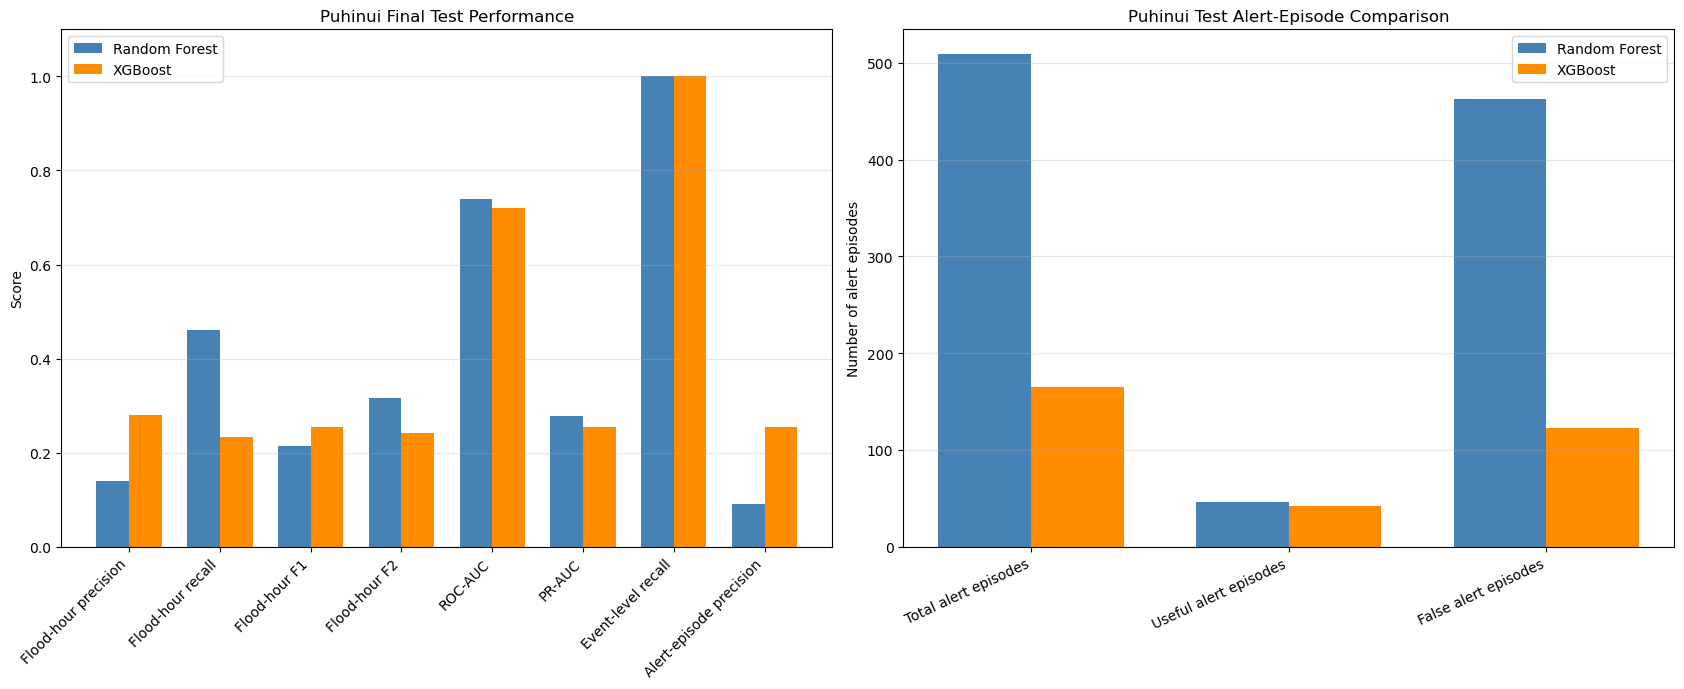

In [56]:
# Plot the final Random Forest and XGBoost comparison

import matplotlib.pyplot as plt
import numpy as np

performance_metrics = [
    "Flood-hour precision",
    "Flood-hour recall",
    "Flood-hour F1",
    "Flood-hour F2",
    "ROC-AUC",
    "PR-AUC",
    "Event-level recall",
    "Alert-episode precision"
]

alert_metrics = [
    "Total alert episodes",
    "Useful alert episodes",
    "False alert episodes"
]

random_forest_performance = (
    model_comparison.loc[
        performance_metrics,
        "Random Forest"
    ].astype(float)
)

xgboost_performance = (
    model_comparison.loc[
        performance_metrics,
        "XGBoost"
    ].astype(float)
)

random_forest_alerts = (
    model_comparison.loc[
        alert_metrics,
        "Random Forest"
    ].astype(float)
)

xgboost_alerts = (
    model_comparison.loc[
        alert_metrics,
        "XGBoost"
    ].astype(float)
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(17, 7)
)

bar_width = 0.36

# Performance metrics
performance_positions = np.arange(
    len(performance_metrics)
)

axes[0].bar(
    performance_positions - bar_width / 2,
    random_forest_performance,
    width=bar_width,
    label="Random Forest",
    color="steelblue"
)

axes[0].bar(
    performance_positions + bar_width / 2,
    xgboost_performance,
    width=bar_width,
    label="XGBoost",
    color="darkorange"
)

axes[0].set_title(
    "Puhinui Final Test Performance"
)
axes[0].set_ylabel("Score")
axes[0].set_ylim(0, 1.1)
axes[0].set_xticks(performance_positions)
axes[0].set_xticklabels(
    performance_metrics,
    rotation=45,
    ha="right"
)
axes[0].legend()
axes[0].grid(
    axis="y",
    alpha=0.3
)

# Alert-episode counts
alert_positions = np.arange(
    len(alert_metrics)
)

axes[1].bar(
    alert_positions - bar_width / 2,
    random_forest_alerts,
    width=bar_width,
    label="Random Forest",
    color="steelblue"
)

axes[1].bar(
    alert_positions + bar_width / 2,
    xgboost_alerts,
    width=bar_width,
    label="XGBoost",
    color="darkorange"
)

axes[1].set_title(
    "Puhinui Test Alert-Episode Comparison"
)
axes[1].set_ylabel("Number of alert episodes")
axes[1].set_xticks(alert_positions)
axes[1].set_xticklabels(
    alert_metrics,
    rotation=25,
    ha="right"
)
axes[1].legend()
axes[1].grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "puhinui_final_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 10. Final Model Comparison and Interpretation

Random Forest and XGBoost showed different strengths when evaluated on the untouched Puhinui test period. Random Forest achieved higher flood-hour recall (0.460), F2-score (0.316), ROC-AUC (0.739), and PR-AUC (0.279). It therefore identified a larger proportion of flood-risk hours and is the more safety-oriented model when missed warning hours are considered more costly than false alarms.

XGBoost achieved higher flood-hour precision (0.280 versus 0.140) and F1-score (0.254 versus 0.215). It also produced substantially fewer alerts. XGBoost generated 165 alert episodes, compared with 509 from Random Forest, and reduced false-alert episodes from 463 to 123, representing a 73.4% reduction. Its alert-episode precision was 0.255, approximately 2.82 times the Random Forest value of 0.090.

Both models detected all 20 flood-risk episodes in the test period, producing an event-level recall of 1.000. However, an event was considered detected when at least one hour within that risk episode was correctly predicted. Consequently, perfect event-level recall does not mean that every risk hour was detected.

Overall, Random Forest provides greater warning coverage, whereas XGBoost produces fewer and more precise alerts. XGBoost may therefore be more suitable for an operational decision-support dashboard where excessive false alerts could cause alert fatigue. Random Forest remains valuable as a more sensitive safety-oriented model. The final deployment decision should reflect the catchment managers' preferred balance between missed warning hours and false-alert burden.

In [57]:
# PREPARE PUHINUI DATA FOR GAUSSIAN NAIVE BAYES

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB

required_variables = [
    "X_train",
    "y_train",
    "X_validation",
    "y_validation",
    "X_test",
    "y_test"
]

missing_variables = [
    name
    for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        f"Missing required variables: {missing_variables}"
    )

assert X_train.shape[1] == X_validation.shape[1]
assert X_train.shape[1] == X_test.shape[1]

assert not X_train.isna().any().any()
assert not X_validation.isna().any().any()
assert not X_test.isna().any().any()

assert set(y_train.unique()).issubset({0, 1})
assert set(y_validation.unique()).issubset({0, 1})
assert set(y_test.unique()).issubset({0, 1})

print(
    f"Training: {X_train.shape[0]} rows, "
    f"{X_train.shape[1]} features, "
    f"{int(y_train.sum())} high-risk rows"
)

print(
    f"Validation: {X_validation.shape[0]} rows, "
    f"{X_validation.shape[1]} features, "
    f"{int(y_validation.sum())} high-risk rows"
)

print(
    f"Test: {X_test.shape[0]} rows, "
    f"{X_test.shape[1]} features, "
    f"{int(y_test.sum())} high-risk rows"
)

Training: 59545 rows, 36 features, 1406 high-risk rows
Validation: 14265 rows, 36 features, 457 high-risk rows
Test: 14423 rows, 36 features, 567 high-risk rows


In [59]:
# TUNE PUHINUI GAUSSIAN NAIVE BAYES

import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)

var_smoothing_values = np.logspace(-12, 8, 41)
naive_bayes_tuning_rows = []

for var_smoothing in var_smoothing_values:

    candidate_model = Pipeline([
        ("scaler", StandardScaler()),
        (
            "naive_bayes",
            GaussianNB(var_smoothing=var_smoothing)
        )
    ])

    candidate_model.fit(X_train, y_train)

    validation_probability = (
        candidate_model.predict_proba(X_validation)[:, 1]
    )

    precision_values, recall_values, thresholds = (
        precision_recall_curve(
            y_validation,
            validation_probability
        )
    )

    f2_values = (
        5 * precision_values[:-1] * recall_values[:-1] /
        (
            4 * precision_values[:-1] +
            recall_values[:-1]
        )
    )

    f2_values = np.nan_to_num(f2_values)

    best_threshold_position = int(np.argmax(f2_values))

    naive_bayes_tuning_rows.append({
        "var_smoothing": var_smoothing,
        "selected_threshold":
            thresholds[best_threshold_position],
        "validation_precision":
            precision_values[best_threshold_position],
        "validation_recall":
            recall_values[best_threshold_position],
        "validation_f2":
            f2_values[best_threshold_position],
        "validation_roc_auc":
            roc_auc_score(
                y_validation,
                validation_probability
            ),
        "validation_pr_auc":
            average_precision_score(
                y_validation,
                validation_probability
            )
    })

puhinui_naive_bayes_tuning_results = (
    pd.DataFrame(naive_bayes_tuning_rows)
)

best_naive_bayes_result = (
    puhinui_naive_bayes_tuning_results
    .sort_values(
        [
            "validation_f2",
            "validation_pr_auc",
            "validation_roc_auc"
        ],
        ascending=False
    )
    .iloc[0]
)

selected_var_smoothing = float(
    best_naive_bayes_result["var_smoothing"]
)

selected_probability_threshold = float(
    best_naive_bayes_result["selected_threshold"]
)

print(
    "Selected var_smoothing:",
    f"{selected_var_smoothing:.6e}"
)

print(
    "Selected probability threshold:",
    f"{selected_probability_threshold:.6e}"
)

print(
    "Maximum validation F2:",
    f"{best_naive_bayes_result['validation_f2']:.4f}"
)

display(
    puhinui_naive_bayes_tuning_results
    .sort_values(
        "validation_f2",
        ascending=False
    )
    .head(10)
    .round(4)
)

Selected var_smoothing: 3.162278e+02
Selected probability threshold: 1.563511e-02
Maximum validation F2: 0.3538


,var_smoothing,selected_threshold,validation_precision,validation_recall,validation_f2,validation_roc_auc,validation_pr_auc
29,316.228,0.016,0.255,0.392,0.354,0.783,0.290
28,100.000,0.007,0.245,0.396,0.352,0.782,0.291
27,31.623,0.001,0.173,0.468,0.349,0.778,0.281
30,1000.000,0.021,0.251,0.381,0.345,0.779,0.288
31,3162.278,0.023,0.250,0.381,0.345,0.774,0.289
32,10000.000,0.023,0.250,0.381,0.345,0.774,0.289
33,31622.777,0.024,0.250,0.381,0.345,0.774,0.290
40,100000000.000,0.024,0.250,0.381,0.345,0.774,0.290
34,100000.000,0.024,0.250,0.381,0.345,0.774,0.290
35,316227.766,0.024,0.250,0.381,0.345,0.774,0.290


In [60]:
# FIT FINAL PUHINUI GAUSSIAN NAIVE BAYES MODEL

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

puhinui_naive_bayes_model = Pipeline([
    ("scaler", StandardScaler()),
    (
        "naive_bayes",
        GaussianNB(
            var_smoothing=selected_var_smoothing
        )
    )
])

puhinui_naive_bayes_model.fit(X_train, y_train)

training_probability_nb = (
    puhinui_naive_bayes_model
    .predict_proba(X_train)[:, 1]
)

validation_probability_nb = (
    puhinui_naive_bayes_model
    .predict_proba(X_validation)[:, 1]
)

validation_prediction_nb = (
    validation_probability_nb >=
    selected_probability_threshold
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_validation,
    validation_prediction_nb,
    labels=[0, 1]
).ravel()

puhinui_naive_bayes_validation_results = pd.Series({
    "selected_threshold":
        selected_probability_threshold,
    "accuracy":
        accuracy_score(
            y_validation,
            validation_prediction_nb
        ),
    "balanced_accuracy":
        balanced_accuracy_score(
            y_validation,
            validation_prediction_nb
        ),
    "precision":
        precision_score(
            y_validation,
            validation_prediction_nb,
            zero_division=0
        ),
    "recall":
        recall_score(
            y_validation,
            validation_prediction_nb,
            zero_division=0
        ),
    "f1_score":
        f1_score(
            y_validation,
            validation_prediction_nb,
            zero_division=0
        ),
    "f2_score":
        fbeta_score(
            y_validation,
            validation_prediction_nb,
            beta=2,
            zero_division=0
        ),
    "roc_auc":
        roc_auc_score(
            y_validation,
            validation_probability_nb
        ),
    "pr_auc":
        average_precision_score(
            y_validation,
            validation_probability_nb
        ),
    "true_negatives": tn,
    "false_positives": fp,
    "false_negatives": fn,
    "true_positives": tp
})

print(
    "Puhinui Gaussian Naive Bayes fitted successfully."
)

display(
    puhinui_naive_bayes_validation_results
    .to_frame("value")
    .round(4)
)

Puhinui Gaussian Naive Bayes fitted successfully.


,value
selected_threshold,0.016
accuracy,0.944
balanced_accuracy,0.677
precision,0.255
recall,0.392
f1_score,0.309
f2_score,0.354
roc_auc,0.783
pr_auc,0.290
true_negatives,13285.000


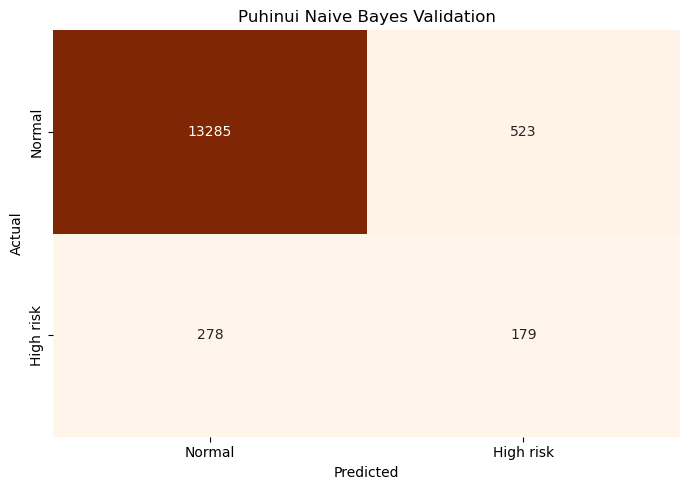

Validation classification report:

              precision    recall  f1-score   support

      Normal     0.9795    0.9621    0.9707     13808
   High risk     0.2550    0.3917    0.3089       457

    accuracy                         0.9438     14265
   macro avg     0.6172    0.6769    0.6398     14265
weighted avg     0.9563    0.9438    0.9495     14265



In [61]:
# PUHINUI NAIVE BAYES VALIDATION CONFUSION MATRIX

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import classification_report

puhinui_naive_bayes_validation_confusion = (
    confusion_matrix(
        y_validation,
        validation_prediction_nb,
        labels=[0, 1]
    )
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    puhinui_naive_bayes_validation_confusion,
    annot=True,
    fmt="d",
    cmap="Oranges",
    cbar=False,
    xticklabels=["Normal", "High risk"],
    yticklabels=["Normal", "High risk"]
)

plt.title("Puhinui Naive Bayes Validation")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

print("Validation classification report:\n")

print(
    classification_report(
        y_validation,
        validation_prediction_nb,
        target_names=["Normal", "High risk"],
        digits=4,
        zero_division=0
    )
)

In [62]:
# EVALUATE PUHINUI NAIVE BAYES ON THE UNTOUCHED TEST SET

test_probability_nb = (
    puhinui_naive_bayes_model
    .predict_proba(X_test)[:, 1]
)

test_prediction_nb = (
    test_probability_nb >=
    selected_probability_threshold
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_prediction_nb,
    labels=[0, 1]
).ravel()

puhinui_naive_bayes_test_results = pd.Series({
    "model": "Gaussian Naive Bayes",
    "var_smoothing": selected_var_smoothing,
    "selected_threshold":
        selected_probability_threshold,
    "rows": len(y_test),
    "actual_high_risk": int(y_test.sum()),
    "predicted_high_risk":
        int(test_prediction_nb.sum()),
    "accuracy":
        accuracy_score(y_test, test_prediction_nb),
    "balanced_accuracy":
        balanced_accuracy_score(
            y_test,
            test_prediction_nb
        ),
    "precision":
        precision_score(
            y_test,
            test_prediction_nb,
            zero_division=0
        ),
    "recall":
        recall_score(
            y_test,
            test_prediction_nb,
            zero_division=0
        ),
    "f1_score":
        f1_score(
            y_test,
            test_prediction_nb,
            zero_division=0
        ),
    "f2_score":
        fbeta_score(
            y_test,
            test_prediction_nb,
            beta=2,
            zero_division=0
        ),
    "roc_auc":
        roc_auc_score(
            y_test,
            test_probability_nb
        ),
    "pr_auc":
        average_precision_score(
            y_test,
            test_probability_nb
        ),
    "true_negatives": tn,
    "false_positives": fp,
    "false_negatives": fn,
    "true_positives": tp
})

puhinui_naive_bayes_test_predictions = pd.DataFrame({
    "timestamp": test_data["timestamp"].to_numpy(),
    "observed_high_water_risk_24h":
        y_test.to_numpy(),
    "naive_bayes_score":
        test_probability_nb,
    "predicted_high_water_risk_24h":
        test_prediction_nb,
    "rainfall_mm":
        test_data["rainfall_mm"].to_numpy(),
    "discharge_m3s":
        test_data["discharge_m3s"].to_numpy(),
    "water_level_m":
        test_data["water_level_m"].to_numpy()
})

print(
    "PUHINUI GAUSSIAN NAIVE BAYES FINAL TEST RESULTS"
)

display(
    puhinui_naive_bayes_test_results
    .to_frame("value")
    .round(4)
)

print(
    "\nTest prediction rows:",
    len(puhinui_naive_bayes_test_predictions)
)

display(
    puhinui_naive_bayes_test_predictions.head()
)

PUHINUI GAUSSIAN NAIVE BAYES FINAL TEST RESULTS


,value
model,Gaussian Naive Bayes
var_smoothing,316.228
selected_threshold,0.016
rows,14423
actual_high_risk,567
predicted_high_risk,650
accuracy,0.940
balanced_accuracy,0.640
precision,0.274
recall,0.314



Test prediction rows: 14423


,timestamp,observed_high_water_risk_24h,naive_bayes_score,predicted_high_water_risk_24h,rainfall_mm,discharge_m3s,water_level_m
0,2024-05-08 08:00:00,0,0.013,0,0.000,0.061,0.148
1,2024-05-08 09:00:00,0,0.013,0,0.000,0.060,0.147
2,2024-05-08 10:00:00,0,0.013,0,0.000,0.060,0.147
3,2024-05-08 11:00:00,0,0.013,0,0.000,0.059,0.146
4,2024-05-08 12:00:00,0,0.013,0,0.000,0.059,0.146


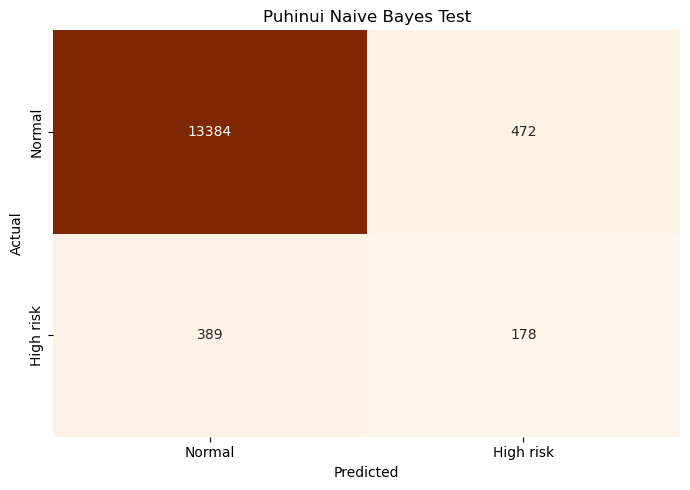

Test classification report:

              precision    recall  f1-score   support

      Normal     0.9718    0.9659    0.9688     13856
   High risk     0.2738    0.3139    0.2925       567

    accuracy                         0.9403     14423
   macro avg     0.6228    0.6399    0.6307     14423
weighted avg     0.9443    0.9403    0.9422     14423



In [63]:
# PUHINUI NAIVE BAYES TEST CONFUSION MATRIX

puhinui_naive_bayes_test_confusion = (
    confusion_matrix(
        y_test,
        test_prediction_nb,
        labels=[0, 1]
    )
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    puhinui_naive_bayes_test_confusion,
    annot=True,
    fmt="d",
    cmap="Oranges",
    cbar=False,
    xticklabels=["Normal", "High risk"],
    yticklabels=["Normal", "High risk"]
)

plt.title("Puhinui Naive Bayes Test")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

print("Test classification report:\n")

print(
    classification_report(
        y_test,
        test_prediction_nb,
        target_names=["Normal", "High risk"],
        digits=4,
        zero_division=0
    )
)

In [64]:
# PUHINUI NAIVE BAYES EVENT-LEVEL TEST RESULTS

def assign_episode_ids(timestamps, binary_values):
    timestamps = pd.Series(
        pd.to_datetime(timestamps)
    ).reset_index(drop=True)

    values = pd.Series(
        np.asarray(binary_values, dtype=int)
    ).reset_index(drop=True)

    previous_positive = values.shift(
        1,
        fill_value=0
    ).eq(1)

    consecutive_hour = timestamps.diff().eq(
        pd.Timedelta(hours=1)
    )

    episode_start = (
        values.eq(1) &
        (
            ~previous_positive |
            ~consecutive_hour
        )
    )

    episode_ids = episode_start.cumsum()

    return episode_ids.where(
        values.eq(1),
        0
    ).astype(int)


event_evaluation_nb = pd.DataFrame({
    "timestamp":
        test_data["timestamp"].to_numpy(),
    "actual":
        y_test.to_numpy(),
    "predicted":
        test_prediction_nb,
    "naive_bayes_score":
        test_probability_nb,
    "water_level_m":
        test_data["water_level_m"].to_numpy()
})

event_evaluation_nb["actual_event_id"] = (
    assign_episode_ids(
        event_evaluation_nb["timestamp"],
        event_evaluation_nb["actual"]
    )
)

event_rows = []

actual_events = event_evaluation_nb[
    event_evaluation_nb["actual_event_id"] > 0
].groupby("actual_event_id")

for event_id, event_data in actual_events:

    detected_hours = int(
        event_data["predicted"].sum()
    )

    event_hours = len(event_data)

    event_rows.append({
        "event_id": int(event_id),
        "event_start":
            event_data["timestamp"].min(),
        "event_end":
            event_data["timestamp"].max(),
        "event_hours":
            event_hours,
        "detected_hours":
            detected_hours,
        "maximum_naive_bayes_score":
            event_data["naive_bayes_score"].max(),
        "mean_naive_bayes_score":
            event_data["naive_bayes_score"].mean(),
        "maximum_water_level_m":
            event_data["water_level_m"].max(),
        "event_detected":
            detected_hours > 0,
        "hourly_detection_percentage":
            100 * detected_hours / event_hours
    })

puhinui_naive_bayes_event_results = pd.DataFrame(
    event_rows
)

total_actual_events = len(
    puhinui_naive_bayes_event_results
)

events_detected = int(
    puhinui_naive_bayes_event_results[
        "event_detected"
    ].sum()
)

event_level_recall = (
    events_detected / total_actual_events
    if total_actual_events else np.nan
)

puhinui_naive_bayes_event_summary = pd.Series({
    "physical_high_risk_events":
        total_actual_events,
    "events_detected":
        events_detected,
    "event_level_recall":
        event_level_recall
})

print(
    "Physical high-risk events:",
    total_actual_events
)

print(
    "Events detected:",
    events_detected
)

print(
    "Event-level recall:",
    f"{event_level_recall:.3f}"
)

display(
    puhinui_naive_bayes_event_results.round(4)
)

Physical high-risk events: 20
Events detected: 20
Event-level recall: 1.000


,event_id,event_start,event_end,event_hours,detected_hours,maximum_naive_bayes_score,mean_naive_bayes_score,maximum_water_level_m,event_detected,hourly_detection_percentage
0,1,2024-05-19 23:00:00,2024-05-21 02:00:00,28,6,0.058,0.019,1.393,True,21.429
1,2,2024-06-13 03:00:00,2024-06-14 13:00:00,35,12,0.025,0.016,0.984,True,34.286
2,3,2024-06-16 00:00:00,2024-06-17 01:00:00,26,5,0.023,0.015,0.924,True,19.231
3,4,2024-06-22 05:00:00,2024-06-23 06:00:00,26,6,0.028,0.015,1.035,True,23.077
4,5,2024-08-31 02:00:00,2024-09-01 06:00:00,29,9,0.063,0.020,1.500,True,31.035
5,6,2024-10-02 03:00:00,2024-10-03 05:00:00,27,9,0.030,0.017,1.067,True,33.333
6,7,2024-11-14 14:00:00,2024-11-15 15:00:00,26,7,0.026,0.015,0.892,True,26.923
7,8,2025-02-10 21:00:00,2025-02-11 20:00:00,24,2,0.029,0.014,0.845,True,8.333
8,9,2025-04-18 03:00:00,2025-04-19 05:00:00,27,4,0.034,0.016,1.131,True,14.815
9,10,2025-05-08 18:00:00,2025-05-09 20:00:00,27,14,0.030,0.017,1.073,True,51.852


In [65]:
# PUHINUI NAIVE BAYES ALERT-EPISODE RESULTS

alert_evaluation_nb = event_evaluation_nb.copy()

alert_evaluation_nb["alert_id"] = (
    assign_episode_ids(
        alert_evaluation_nb["timestamp"],
        alert_evaluation_nb["predicted"]
    )
)

alert_rows = []

predicted_alerts = alert_evaluation_nb[
    alert_evaluation_nb["alert_id"] > 0
].groupby("alert_id")

for alert_id, alert_data in predicted_alerts:

    actual_risk_hours = int(
        alert_data["actual"].sum()
    )

    alert_rows.append({
        "alert_id": int(alert_id),
        "alert_start":
            alert_data["timestamp"].min(),
        "alert_end":
            alert_data["timestamp"].max(),
        "alert_hours":
            len(alert_data),
        "actual_risk_hours":
            actual_risk_hours,
        "maximum_naive_bayes_score":
            alert_data["naive_bayes_score"].max(),
        "mean_naive_bayes_score":
            alert_data["naive_bayes_score"].mean(),
        "associated_with_risk":
            actual_risk_hours > 0
    })

puhinui_naive_bayes_alert_results = pd.DataFrame(
    alert_rows
)

total_alert_episodes = len(
    puhinui_naive_bayes_alert_results
)

risk_associated_alert_episodes = int(
    puhinui_naive_bayes_alert_results[
        "associated_with_risk"
    ].sum()
)

false_alert_episodes = (
    total_alert_episodes -
    risk_associated_alert_episodes
)

alert_episode_precision = (
    risk_associated_alert_episodes /
    total_alert_episodes
    if total_alert_episodes else np.nan
)

print(
    "Total predicted alert episodes:",
    total_alert_episodes
)

print(
    "Risk-associated alert episodes:",
    risk_associated_alert_episodes
)

print(
    "False alert episodes:",
    false_alert_episodes
)

print(
    "Alert-episode precision:",
    f"{alert_episode_precision:.3f}"
)

display(
    puhinui_naive_bayes_alert_results.head(20).round(4)
)

Total predicted alert episodes: 88
Risk-associated alert episodes: 27
False alert episodes: 61
Alert-episode precision: 0.307


,alert_id,alert_start,alert_end,alert_hours,actual_risk_hours,maximum_naive_bayes_score,mean_naive_bayes_score,associated_with_risk
0,1,2024-05-15 06:00:00,2024-05-15 10:00:00,5,0,0.019,0.018,False
1,2,2024-05-15 13:00:00,2024-05-15 13:00:00,1,0,0.016,0.016,False
2,3,2024-05-20 21:00:00,2024-05-21 14:00:00,18,6,0.058,0.026,True
3,4,2024-05-29 16:00:00,2024-05-29 16:00:00,1,0,0.016,0.016,False
4,5,2024-06-09 20:00:00,2024-06-10 07:00:00,12,0,0.018,0.017,False
5,6,2024-06-14 02:00:00,2024-06-14 19:00:00,18,12,0.025,0.020,True
6,7,2024-06-14 21:00:00,2024-06-15 02:00:00,6,0,0.017,0.017,False
7,8,2024-06-16 21:00:00,2024-06-17 06:00:00,10,5,0.023,0.019,True
8,9,2024-06-23 01:00:00,2024-06-23 13:00:00,13,6,0.028,0.020,True
9,10,2024-07-01 21:00:00,2024-07-01 22:00:00,2,0,0.016,0.016,False


In [66]:
# PUHINUI NAIVE BAYES TRAINING AND TEST PERFORMANCE

training_prediction_nb = (
    training_probability_nb >=
    selected_probability_threshold
).astype(int)

puhinui_naive_bayes_train_test_comparison = pd.DataFrame({
    "Training": {
        "Accuracy":
            accuracy_score(
                y_train,
                training_prediction_nb
            ),
        "Balanced accuracy":
            balanced_accuracy_score(
                y_train,
                training_prediction_nb
            ),
        "Precision":
            precision_score(
                y_train,
                training_prediction_nb,
                zero_division=0
            ),
        "Recall":
            recall_score(
                y_train,
                training_prediction_nb,
                zero_division=0
            ),
        "F1":
            f1_score(
                y_train,
                training_prediction_nb,
                zero_division=0
            ),
        "F2":
            fbeta_score(
                y_train,
                training_prediction_nb,
                beta=2,
                zero_division=0
            ),
        "ROC-AUC":
            roc_auc_score(
                y_train,
                training_probability_nb
            ),
        "PR-AUC":
            average_precision_score(
                y_train,
                training_probability_nb
            )
    },

    "Test": {
        "Accuracy":
            accuracy_score(
                y_test,
                test_prediction_nb
            ),
        "Balanced accuracy":
            balanced_accuracy_score(
                y_test,
                test_prediction_nb
            ),
        "Precision":
            precision_score(
                y_test,
                test_prediction_nb,
                zero_division=0
            ),
        "Recall":
            recall_score(
                y_test,
                test_prediction_nb,
                zero_division=0
            ),
        "F1":
            f1_score(
                y_test,
                test_prediction_nb,
                zero_division=0
            ),
        "F2":
            fbeta_score(
                y_test,
                test_prediction_nb,
                beta=2,
                zero_division=0
            ),
        "ROC-AUC":
            roc_auc_score(
                y_test,
                test_probability_nb
            ),
        "PR-AUC":
            average_precision_score(
                y_test,
                test_probability_nb
            )
    }
})

print(
    "PUHINUI NAIVE BAYES TRAINING VERSUS TEST PERFORMANCE"
)

display(
    puhinui_naive_bayes_train_test_comparison
    .round(4)
)

PUHINUI NAIVE BAYES TRAINING VERSUS TEST PERFORMANCE


,Training,Test
Accuracy,0.957,0.940
Balanced accuracy,0.655,0.640
Precision,0.223,0.274
Recall,0.339,0.314
F1,0.269,0.292
F2,0.307,0.305
ROC-AUC,0.795,0.726
PR-AUC,0.269,0.268


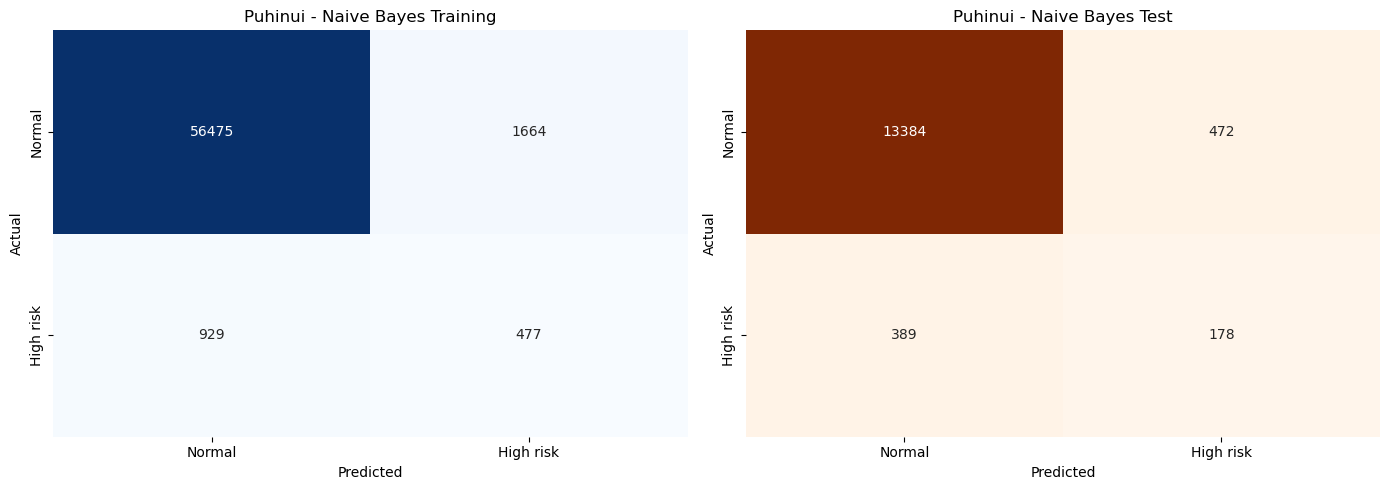

In [68]:
# PUHINUI NAIVE BAYES TRAINING AND TEST CONFUSION MATRICES

puhinui_naive_bayes_training_confusion = confusion_matrix(
    y_train,
    training_prediction_nb,
    labels=[0, 1]
)

puhinui_naive_bayes_test_confusion = confusion_matrix(
    y_test,
    test_prediction_nb,
    labels=[0, 1]
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    puhinui_naive_bayes_training_confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Normal", "High risk"],
    yticklabels=["Normal", "High risk"],
    ax=axes[0]
)

axes[0].set_title("Puhinui - Naive Bayes Training")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    puhinui_naive_bayes_test_confusion,
    annot=True,
    fmt="d",
    cmap="Oranges",
    cbar=False,
    xticklabels=["Normal", "High risk"],
    yticklabels=["Normal", "High risk"],
    ax=axes[1]
)

axes[1].set_title("Puhinui - Naive Bayes Test")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

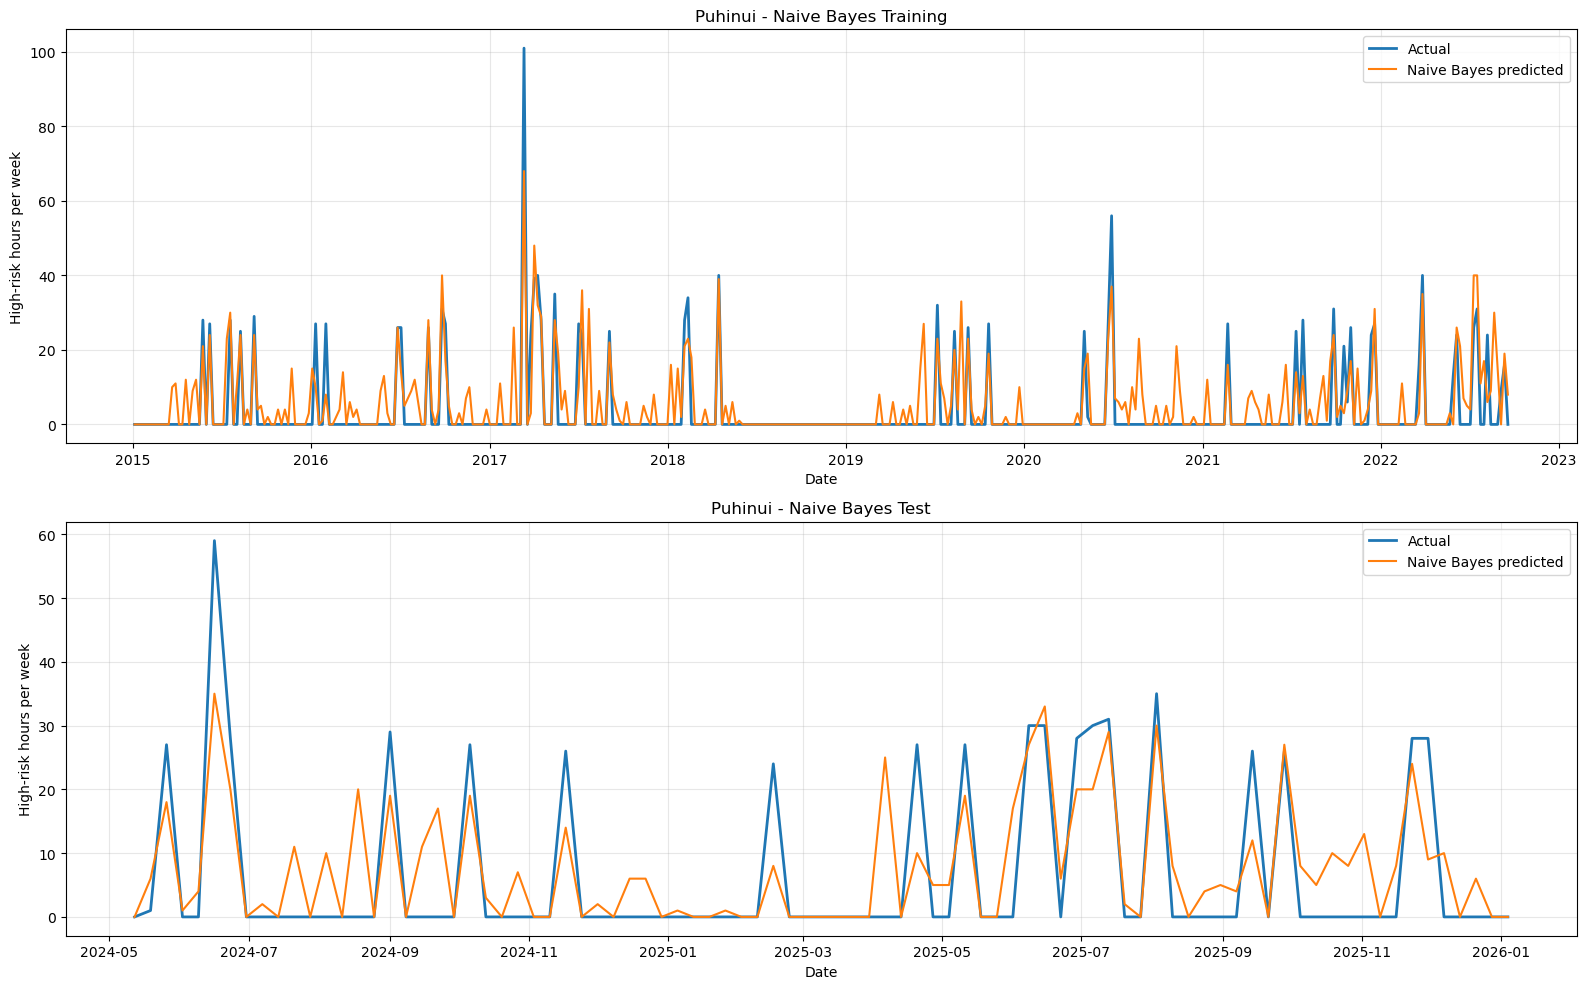

In [70]:
# PUHINUI WEEKLY ACTUAL VERSUS NAIVE BAYES PREDICTIONS

training_weekly_nb = pd.DataFrame({
    "timestamp": pd.to_datetime(training_data["timestamp"]),
    "actual": np.asarray(y_train),
    "predicted": np.asarray(training_prediction_nb)
})

test_weekly_nb = pd.DataFrame({
    "timestamp": pd.to_datetime(test_data["timestamp"]),
    "actual": np.asarray(y_test),
    "predicted": np.asarray(test_prediction_nb)
})

training_weekly_nb = (
    training_weekly_nb
    .set_index("timestamp")[["actual", "predicted"]]
    .resample("W")
    .sum()
)

test_weekly_nb = (
    test_weekly_nb
    .set_index("timestamp")[["actual", "predicted"]]
    .resample("W")
    .sum()
)

fig, axes = plt.subplots(2, 1, figsize=(16, 10))

axes[0].plot(
    training_weekly_nb.index,
    training_weekly_nb["actual"],
    label="Actual",
    linewidth=2
)

axes[0].plot(
    training_weekly_nb.index,
    training_weekly_nb["predicted"],
    label="Naive Bayes predicted",
    linewidth=1.5
)

axes[0].set_title("Puhinui - Naive Bayes Training")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("High-risk hours per week")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    test_weekly_nb.index,
    test_weekly_nb["actual"],
    label="Actual",
    linewidth=2
)

axes[1].plot(
    test_weekly_nb.index,
    test_weekly_nb["predicted"],
    label="Naive Bayes predicted",
    linewidth=1.5
)

axes[1].set_title("Puhinui - Naive Bayes Test")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("High-risk hours per week")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [71]:
# PUHINUI FINAL TEST MODEL COMPARISON

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

model_test_outputs = {
    "Random Forest": (
        random_forest_test_probability,
        random_forest_test_prediction
    ),
    "XGBoost": (
        xgboost_test_probability,
        xgboost_test_prediction
    ),
    "Gaussian Naive Bayes": (
        test_probability_nb,
        test_prediction_nb
    )
}

comparison_rows = []

for model_name, (probability, prediction) in model_test_outputs.items():
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        prediction,
        labels=[0, 1]
    ).ravel()

    comparison_rows.append({
        "model": model_name,
        "accuracy": accuracy_score(y_test, prediction),
        "balanced_accuracy": balanced_accuracy_score(y_test, prediction),
        "precision": precision_score(
            y_test, prediction, zero_division=0
        ),
        "recall": recall_score(
            y_test, prediction, zero_division=0
        ),
        "f1_score": f1_score(
            y_test, prediction, zero_division=0
        ),
        "f2_score": fbeta_score(
            y_test, prediction, beta=2, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_test, probability),
        "pr_auc": average_precision_score(y_test, probability),
        "true_positives": tp,
        "false_negatives": fn,
        "false_positives": fp,
        "true_negatives": tn
    })

puhinui_three_model_test_comparison = (
    pd.DataFrame(comparison_rows)
    .set_index("model")
)

print("PUHINUI FINAL TEST MODEL COMPARISON")
display(
    puhinui_three_model_test_comparison.round(4)
)

PUHINUI FINAL TEST MODEL COMPARISON


,accuracy,balanced_accuracy,precision,recall,f1_score,f2_score,roc_auc,pr_auc,true_positives,false_negatives,false_positives,true_negatives
model,,,,,,,,,,,,
Random Forest,0.868,0.672,0.140,0.460,0.215,0.316,0.739,0.279,261,306,1604,12252
XGBoost,0.946,0.604,0.280,0.233,0.254,0.241,0.721,0.254,132,435,340,13516
Gaussian Naive Bayes,0.940,0.640,0.274,0.314,0.292,0.305,0.726,0.268,178,389,472,13384


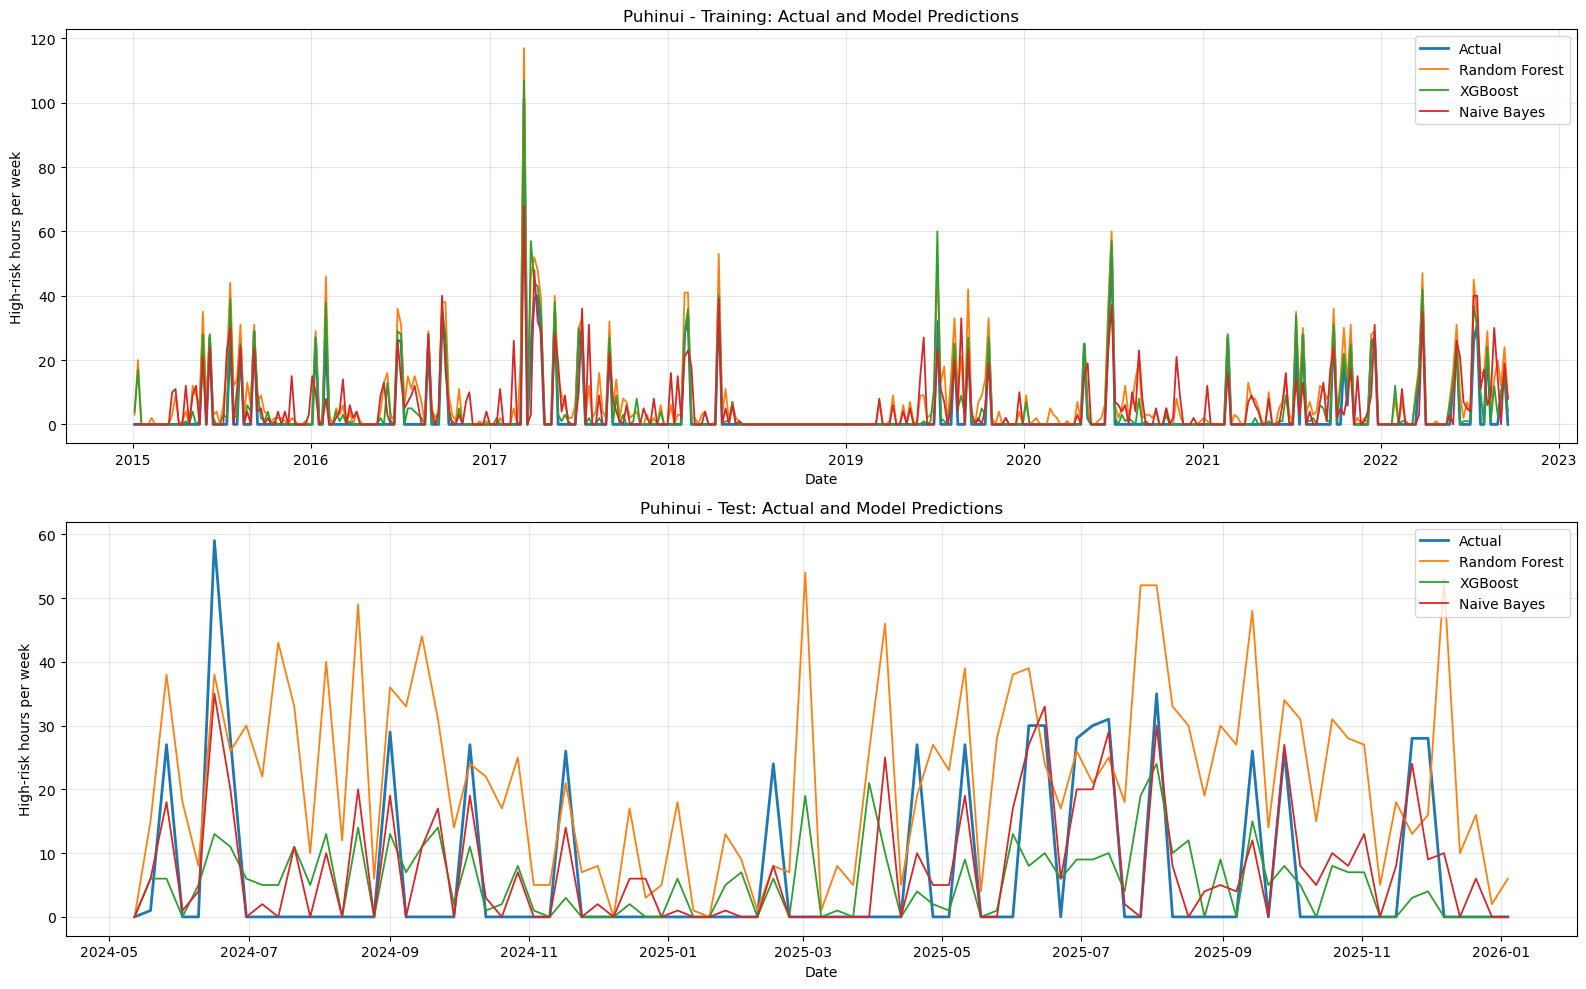

In [73]:
# PUHINUI WEEKLY ACTUAL AND THREE-MODEL PREDICTIONS

random_forest_training_probability = (
    random_forest_model.predict_proba(X_train)[:, 1]
)

random_forest_training_prediction = (
    random_forest_training_probability
    >= random_forest_selected_threshold
).astype(int)

xgboost_training_probability = (
    xgboost_model.predict_proba(X_train)[:, 1]
)

xgboost_training_prediction = (
    xgboost_training_probability
    >= xgboost_selected_threshold
).astype(int)

training_model_predictions = pd.DataFrame({
    "timestamp": pd.to_datetime(training_data["timestamp"]),
    "actual": np.asarray(y_train),
    "random_forest": random_forest_training_prediction,
    "xgboost": xgboost_training_prediction,
    "naive_bayes": training_prediction_nb
})

test_model_predictions = pd.DataFrame({
    "timestamp": pd.to_datetime(test_data["timestamp"]),
    "actual": np.asarray(y_test),
    "random_forest": random_forest_test_prediction,
    "xgboost": xgboost_test_prediction,
    "naive_bayes": test_prediction_nb
})

training_model_predictions_weekly = (
    training_model_predictions
    .set_index("timestamp")
    .resample("W")
    .sum()
)

test_model_predictions_weekly = (
    test_model_predictions
    .set_index("timestamp")
    .resample("W")
    .sum()
)

fig, axes = plt.subplots(2, 1, figsize=(16, 10))

for column, label in [
    ("actual", "Actual"),
    ("random_forest", "Random Forest"),
    ("xgboost", "XGBoost"),
    ("naive_bayes", "Naive Bayes")
]:
    axes[0].plot(
        training_model_predictions_weekly.index,
        training_model_predictions_weekly[column],
        label=label,
        linewidth=2 if column == "actual" else 1.3
    )

axes[0].set_title("Puhinui - Training: Actual and Model Predictions")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("High-risk hours per week")
axes[0].legend()
axes[0].grid(alpha=0.3)

for column, label in [
    ("actual", "Actual"),
    ("random_forest", "Random Forest"),
    ("xgboost", "XGBoost"),
    ("naive_bayes", "Naive Bayes")
]:
    axes[1].plot(
        test_model_predictions_weekly.index,
        test_model_predictions_weekly[column],
        label=label,
        linewidth=2 if column == "actual" else 1.3
    )

axes[1].set_title("Puhinui - Test: Actual and Model Predictions")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("High-risk hours per week")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

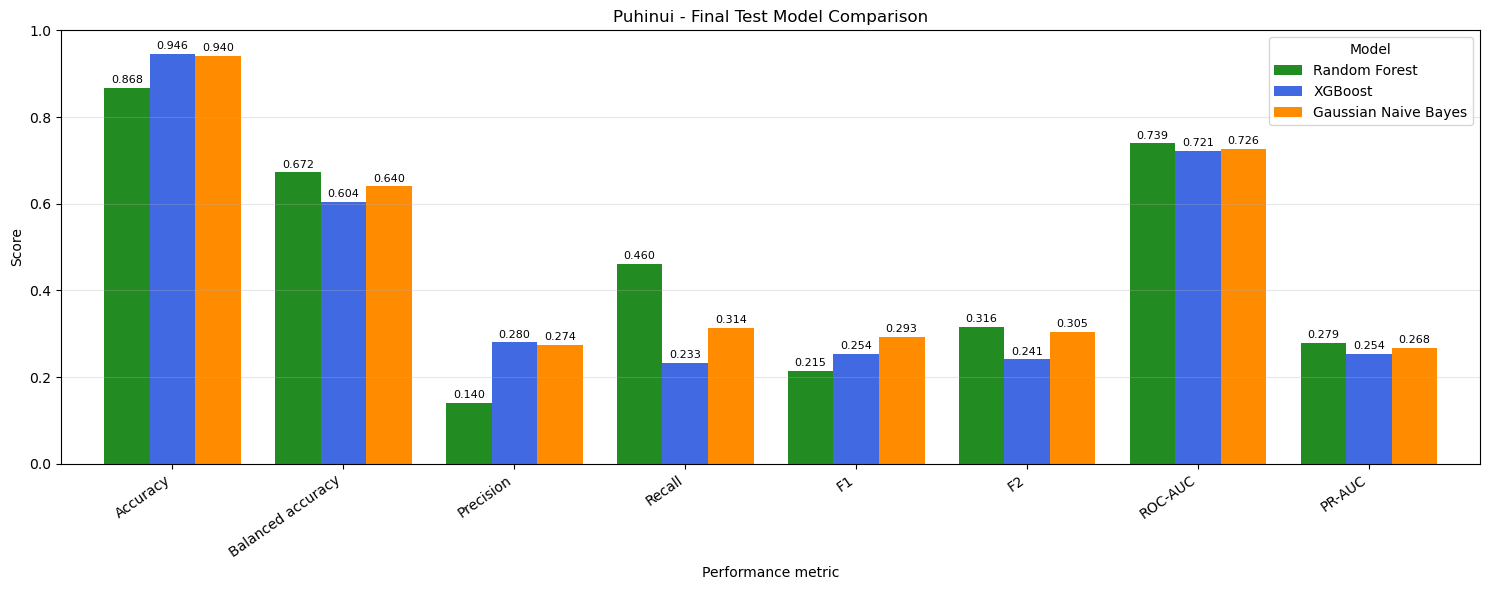

In [75]:
# PUHINUI FINAL TEST PERFORMANCE COMPARISON GRAPH

performance_metrics = [
    "accuracy",
    "balanced_accuracy",
    "precision",
    "recall",
    "f1_score",
    "f2_score",
    "roc_auc",
    "pr_auc"
]

metric_labels = [
    "Accuracy",
    "Balanced accuracy",
    "Precision",
    "Recall",
    "F1",
    "F2",
    "ROC-AUC",
    "PR-AUC"
]

plot_data = (
    puhinui_three_model_test_comparison[performance_metrics]
    .transpose()
)

plot_data.index = metric_labels

ax = plot_data.plot(
    kind="bar",
    figsize=(15, 6),
    width=0.8,
    color=["forestgreen", "royalblue", "darkorange"]
)

ax.set_title("Puhinui - Final Test Model Comparison")
ax.set_xlabel("Performance metric")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend(title="Model")
ax.grid(axis="y", alpha=0.3)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=2,
        fontsize=8
    )

plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

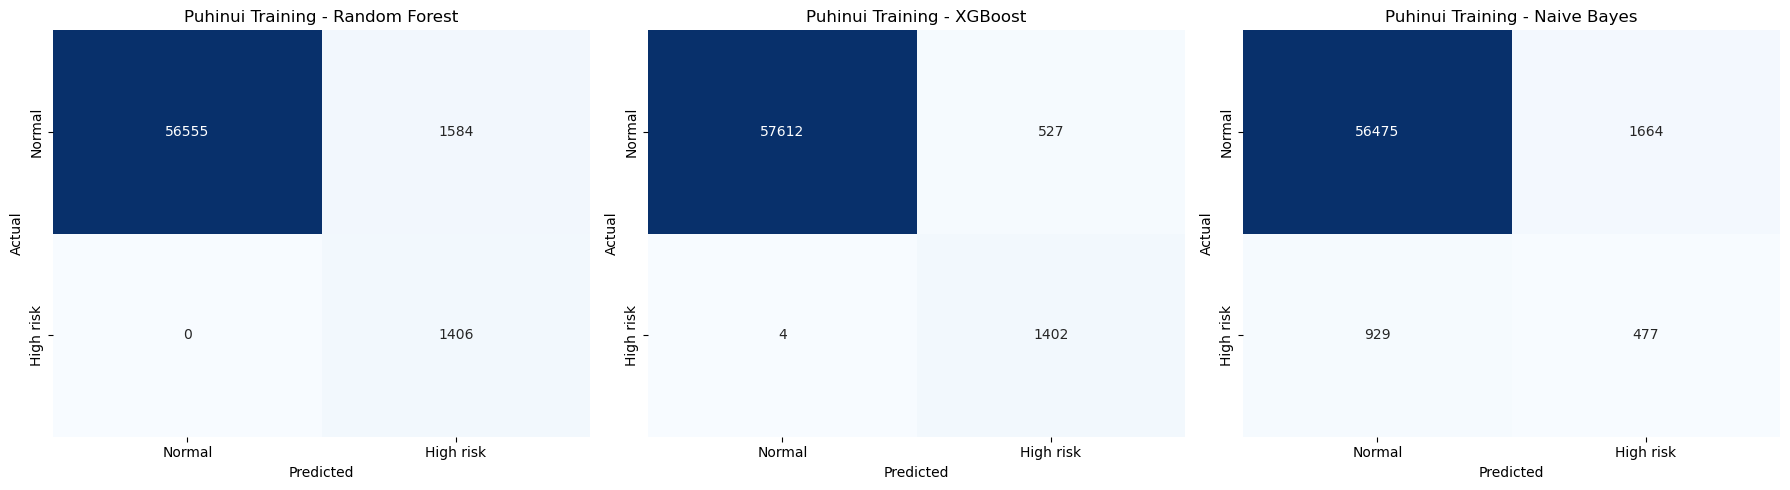

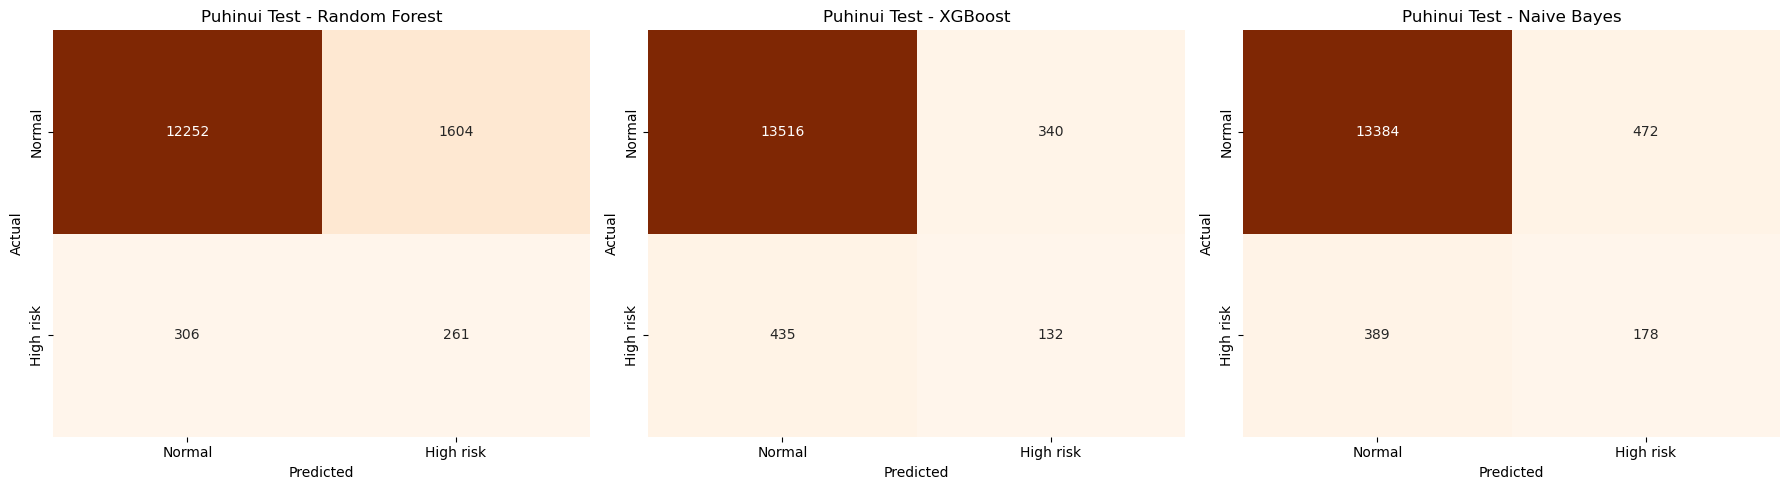

In [77]:
# PUHINUI TRAINING AND TEST CONFUSION MATRICES FOR ALL THREE MODELS

training_predictions = {
    "Random Forest": random_forest_training_prediction,
    "XGBoost": xgboost_training_prediction,
    "Naive Bayes": training_prediction_nb
}

test_predictions = {
    "Random Forest": random_forest_test_prediction,
    "XGBoost": xgboost_test_prediction,
    "Naive Bayes": test_prediction_nb
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for axis, (model_name, prediction) in zip(
    axes,
    training_predictions.items()
):
    matrix = confusion_matrix(
        y_train,
        prediction,
        labels=[0, 1]
    )

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Normal", "High risk"],
        yticklabels=["Normal", "High risk"],
        ax=axis
    )

    axis.set_title(f"Puhinui Training - {model_name}")
    axis.set_xlabel("Predicted")
    axis.set_ylabel("Actual")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for axis, (model_name, prediction) in zip(
    axes,
    test_predictions.items()
):
    matrix = confusion_matrix(
        y_test,
        prediction,
        labels=[0, 1]
    )

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Oranges",
        cbar=False,
        xticklabels=["Normal", "High risk"],
        yticklabels=["Normal", "High risk"],
        ax=axis
    )

    axis.set_title(f"Puhinui Test - {model_name}")
    axis.set_xlabel("Predicted")
    axis.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [78]:
# PUHINUI RECOMMENDED MODEL

recommended_model = (
    puhinui_three_model_test_comparison["f2_score"]
    .idxmax()
)

recommended_results = (
    puhinui_three_model_test_comparison
    .loc[recommended_model]
)

print(f"Recommended Puhinui model: {recommended_model}")
print(
    "Reason: This model has the highest test F2 score, "
    "which gives greater importance to detecting high-risk hours."
)

display(
    recommended_results.to_frame(name="value").round(4)
)

Recommended Puhinui model: Random Forest
Reason: This model has the highest test F2 score, which gives greater importance to detecting high-risk hours.


,value
accuracy,0.868
balanced_accuracy,0.672
precision,0.140
recall,0.460
f1_score,0.215
f2_score,0.316
roc_auc,0.739
pr_auc,0.279
true_positives,261.000
false_negatives,306.000
